In [ ]:
import numpy as np
import scipy.optimize as opt
import matplotlib.pyplot as plt
from scipy.optimize import brentq

In [ ]:
#algoritmo 1: lo usamos para simulación exacta
def ALG1(VecinosVs,beta,k):
  y = np.zeros(len(VecinosVs))#los y_v
  x = np.zeros((len(VecinosVs),len(VecinosVs)))#lso xuv
  for i in range(len(VecinosVs)): #para cada vertice
    Yvecinos=[y[u] for u in VecinosVs[i]]#tomamos los y de los vecinos
    Theta=ThetaOptimo(Yvecinos,k)#sacamos theta
    for j in VecinosVs[i]:#para cada vecino
      x[i][j]= (max(0,Theta-y[j])/beta)*(1+(1-Theta)/(fk(Theta,k)))#calc xuv
      x[j][i]=x[i][j]#pues matriz
      y[j]=max(Theta,y[j])#reajustamos yu vecinos
    y[i]=1-Theta#reajustamos yv vertice
  return y,x


In [ ]:
#Este algoritmo 1 lo usamos para montecarlo
def alg1(vecinos, eps):
    k, beta = 1 + 2 * eps, 2 - eps
    #assert beta >= beta_estrella(k) - 1e-12, "beta < beta*(f): el fraccionario puede ser infactible"
    n = len(vecinos)
    y = np.zeros(n)
    x = [None] * n          # x[i][a] = x_{u v} con u = vecinos[i][a], v = i
    y_antes = [None] * n    # y_u de los vecinos justo ANTES de que llegue i
    for v in range(n):
        vec = vecinos[v]
        yv = y[vec].copy()
        y_antes[v] = yv
        th = theta_optimo(yv, k)
        inc = np.maximum(0.0, th - yv)
        if len(vec) == 0:
            x[v] = np.zeros(0)
        else:
            fac = 1.0 if th >= 1.0 and fk(th, k) == 0 else 1 + (1 - th) / fk(th, k)
            x[v] = np.where(inc > 0, inc / beta * fac, 0.0)
        y[vec] = np.maximum(y[vec], th)  #indexación vectorizada con numpy, creo que es más rapido que actualizar y[j] con lista por compresión
        y[v] = 1 - th
    return x, y, y_antes, beta


In [ ]:
#fucnion de fk(theta), beta*, theta
def fk(theta,k):
  return ((((1+k)/2)-theta)**((1+k)/(2*k)))*((((k-1)/2)+theta)**((k-1)/(2*k)))

def beta_estrella(k):
    return 1 + fk(0.0, k)
def theta_optimo(y_vec, k):
    #Mayor theta<=1 con sum (theta-y_u)^+ <= f(theta). g es creciente => un unico cero.
    y_vec = np.asarray(y_vec, float)
    if len(y_vec) == 0:
        return 1.0
    g = lambda t: np.maximum(0.0, t - y_vec).sum() - fk(t, k)
    if g(1.0) <= 0:
        return 1.0
    return brentq(g, 0.0, 1.0, xtol=1e-14)
#La modificación que le hice al theta optimo es el solver: la función g es estrictamente creciente y por ende tiene un unico cero
# o ninguno, asi que anduve averiguando y brentq es exacto y no depende del punto inicial, ademas SLSQP trabaja mal con el maximo pq no es diff



In [ ]:
#funcion que entrega el theta del problema a resolver en alg1 (igual se usa en alg 3)

#me los pseudo dió deepseek, quería ver como era lo de optimizar con scipy
def ThetaOptimo(vecinos,k):
    if len(vecinos)==0:
        return 1.0#evaluar esto, caso vacio

    def objective(theta):
        return -theta[0]

    def constraint(theta):
        th = theta[0]
        lhs = np.sum(np.maximum(0.0, th - vecinos))
        return fk(theta,k) - lhs

    x0 = np.array([0.5])

    bounds = [(0.0, 1.0)]
    constraints = [{'type': 'ineq', 'fun': constraint}]

    res = opt.minimize(
        objective,
        x0,
        method='SLSQP',
        bounds=bounds,
        constraints=constraints,
        options={'ftol': 1e-12, 'maxiter': 200}
    )

    if not res.success:
        # Si falla, intentamos con otro punto inicial
        x0 = np.array([1.0])
        res = opt.minimize(
            objective,
            x0,
            method='SLSQP',
            bounds=bounds,
            constraints=constraints,
            options={'ftol': 1e-12, 'maxiter': 200}
        )

    return float(res.x[0])

In [ ]:
#funcion que comprueba si un vertice ya esta matcheado, los -1 es cuando no se eliguio uno, por lo tanto no se les puede elegir
def libre(indice,matching):
  if indice==-1:
    return False
  for i in range(len(matching)):
    if matching[i][indice]==1:
      return False
  return True

  #funcion que elige un indice, es para liedear con el caso desagradable de que znormal no llegue a sumarr 1
def ElegirIndice(vecinos, znormal):
  if np.sum(znormal)==1:
    return np.random.choice(vecinos,p=znormal)
  elif np.sum(znormal)<1:
    candidatos=np.append(vecinos,-1)
    probas=np.append(znormal,1-np.sum(znormal))
    return np.random.choice(candidatos,p=probas)
  else:
    print("Hay alguno malo")
    return -1

In [ ]:

def ALG3(VecinosVs,epsilon):
  beta,k=2-epsilon,1+2*epsilon
  y = np.zeros(len(VecinosVs))#los y_v
  x = np.zeros((len(VecinosVs),len(VecinosVs)))#lso xuv
  M=np.zeros((len(VecinosVs),len(VecinosVs)))
  for i in range(len(VecinosVs)): #para cada vertice
    Yvecinos=[y[u] for u in VecinosVs[i]]#tomamos los y de los vecinos
    Theta=ThetaOptimo(Yvecinos,k)#sacamos theta
    for j in VecinosVs[i]:#para cada vecino
      x[i][j]= (max(0,Theta-y[j])/beta)*(1+(1-Theta)/(fk(Theta,k)))#calc xuv
      x[j][i]=x[i][j]#pues matriz
      y[j]=max(Theta,y[j])#reajustamos yu vecinos
    y[i]=1-Theta#reajustamos yv vertice
    z=np.zeros(len(VecinosVs))
    znormal=np.zeros(len(VecinosVs))
    for j in VecinosVs[i]:
      Pr=1#sacar proba segun 3.3
      z[j]=x[i][j]/Pr
    for j in VecinosVs[i]:
      znormal[j]=z[j]/max(1,np.sum(z))
    elegido1=ElegirIndice(VecinosVs[i],znormal)#np.random.choice(VecinosVs[i],p=znormal)
    elegido2=-1
    if np.sum(z)>1:
      if np.random.uniform(0,1)<=np.sqrt(epsilon):
        elegido2=ElegirIndice(VecinosVs[i],znormal)
        ProbDropping=1#sacar proba segu8n 7}
        if np.random.uniform(0,1)<=ProbDropping:
          elegido2=-1
    if libre(elegido1,M):
      M[i][elegido1]=1
      M[elegido1][i]=1
    elif libre(elegido2,M):
      M[i][elegido2]=1
      M[elegido2][i]=1
  return M




In [ ]:
#IA correccion
#Funcion muestrear: su proposito es sortear, en un solo paso, el vecino que elige cada una de las N replicas. es como un reeplazo de ElegirIndice;
#cum: son las probabilidades acumuladas de los candidatos ( ie, np.cumsum(zn))
#rng.random(N): genera N numeros unifores en (0,1), uno por replica
#searchsorted: busca, para cada uniforme, en que tramo de cum cae, ese tramo es el indice elegido. Si el uniforme supera el ultimo valor de cum, devuelve el numero de vecinos (d) qe en el codigo significa ninnguno
#la creación de este función esta sustentada bajo la teoria de la inversa discreta: La teoría: transformada inversa discreta

"Si X toma los valores 0, …, d−1 con probabilidades p₀, …, p_{d−1} y F(j) = p₀ + … + p_j, entonces para U ~ Uniforme(0,1), X = el menor j tal que U < F(j) tiene exactamente la distribución buscada, porque Pr[X = j] = Pr[F(j−1) ≤ U < F(j)] = F(j) − F(j−1) = p_j. Es un método general: dividir el intervalo [0,1] en tramos de largo p_j y ver en cuál cae el uniforme."
def _muestrear(cum, rng, N):
    """Indice en [0..d]: d = 'ninguno'. cum = probabilidades acumuladas (largo d)."""
    return np.searchsorted(cum, rng.random(N), side="right")
#devuelve una matriz booleanaa libre[N,n] es mucho más rapido ver si un vertice esta libre



#Popuestas Alg2 Y 3 : segun lo que yo entendi en el algoritmo 2 se trabaja con el caso kappa = 1, f(theta) = 1-theta y beta=2, y ahi se cumple que la P[u libre] = 1- y_u exacto,
#En cambio, para el algoritmo 3 P[u libre] ya no tiene forma cerrada y hay que estimarla usando montecarlo, entonces haré una función redondeo que trabaje sobre ambos modos distinguidos por el numero de algoritmo.

def redondeo(vecinos, x, y_antes, eps, N=20000, modo="alg3", dropping=True, seed=0):
    """modo='alg2': eps=0, Pr[u libre]=1-y_u exacto. modo='alg3': Pr[u libre] estimado con las N replicas."""
    rng = np.random.default_rng(seed)
    n = len(vecinos)
    libre = np.ones((N, n), dtype=bool)
    cuenta_aristas = [None] * n          # cuantas replicas emparejaron (v, vecino a)
    for v in range(n):
        vec = np.array(vecinos[v], dtype=int)
        d = len(vec)
        cuenta_aristas[v] = np.zeros(d)
        if d == 0:
            continue
        if modo == "alg2":
            p = 1 - y_antes[v]
        else:
            p = libre[:, vec].mean(axis=0)
        p = np.maximum(p, 1e-9)
        z = x[v] / p
        S = z.sum()
        zn = z / max(1.0, S)
        cum1 = np.cumsum(zn)                                   # si S<1 queda masa 1-S para 'ninguno'
        u1 = _muestrear(cum1, rng, N)
        match = np.full(N, -1)
        ok1 = u1 < d
        ok1[ok1] = libre[np.nonzero(ok1)[0], vec[u1[ok1]]]
        match[ok1] = u1[ok1]
        if modo == "alg3" and S > 1:
            usa2 = rng.random(N) <= np.sqrt(eps)
            u2 = _muestrear(cum1, rng, N)                      # aqui S>1 => cum1[-1]=1, u2<d casi seguro
            u2 = np.minimum(u2, d - 1)
            if dropping:
                Fn = libre[:, vec].astype(float)
                cnt = np.maximum(Fn.sum(axis=0), 1.0)
                cond = (Fn.T @ Fn) / cnt[:, None]              # cond[u,w] = Pr[F_w | F_u]
                seg = zn * np.sqrt(eps) * (zn[None, :] * (1 - cond)).sum(axis=1)   # 2do termino de (7), sin Pr[F_u]
                keep = np.where(seg > 0, np.clip((z - zn) / np.maximum(seg, 1e-300), 0, 1), 1.0)
                usa2 &= rng.random(N) < keep[u2]
            ok2 = usa2 & (match < 0)
            ok2[ok2] = libre[np.nonzero(ok2)[0], vec[u2[ok2]]]
            match[ok2] = u2[ok2]
        r = np.nonzero(match >= 0)[0]
        libre[r, vec[match[r]]] = False
        libre[r, v] = False
        for a in range(d):
            cuenta_aristas[v][a] = (match == a).sum()
    tam = (~libre).sum(axis=1) / 2
    probs = [c / N for c in cuenta_aristas]
    return tam, probs


#tam: tamaño del matching por réplica
#probs: frecuencia empirica de cada arista para comparar con x


In [ ]:
#IA
"""
Banco de pruebas para comparar el redondeo contra el matching optimo.

Requiere (en el mismo notebook): tus funciones  alg1  y  redondeo , y  networkx
(pip install networkx).  Formato de grafo = el tuyo:
    vecinos[v] = lista de vecinos que llegaron ANTES que v   (vertices 0..n-1 en orden de llegada)

Metrica ("ranking"):  razon competitiva  =  E[tamano del matching] / OPT
    - el peor caso (minimo sobre instancias) es lo que mide la competitividad
    - el paper garantiza 1/2 + algo muy pequeno en el peor caso
"""
import numpy as np
import networkx as nx


# =============================================================================
# Conversiones (por si piensas en matrices)
# =============================================================================
def a_grafo(vecinos):
    G = nx.Graph()
    G.add_nodes_from(range(len(vecinos)))
    for v, vec in enumerate(vecinos):
        G.add_edges_from((u, v) for u in vec)
    return G


def a_matriz(vecinos):
    """Matriz de adyacencia simetrica (0/1) del grafo."""
    n = len(vecinos)
    A = np.zeros((n, n), dtype=int)
    for v, vec in enumerate(vecinos):
        for u in vec:
            A[u][v] = A[v][u] = 1
    return A


def desde_matriz(A, orden=None):
    """
    A: matriz de adyacencia simetrica.  orden[k] = vertice de A que llega en la posicion k
    (por defecto 0,1,2,...).  Devuelve `vecinos` con los vertices renombrados por orden de llegada.
    """
    n = len(A)
    orden = list(range(n)) if orden is None else list(orden)
    pos = {v: k for k, v in enumerate(orden)}
    return [[pos[u] for u in orden[:k] if A[orden[k]][u]] for k in range(n)]


# =============================================================================
# MATCHING OPTIMO (maximo cardinal, grafos generales: algoritmo de Edmonds / blossom)
# =============================================================================
def matching_optimo(vecinos):
    """Devuelve (tamano, lista de pares (u,v) con u<v). El orden de llegada no importa."""
    G = a_grafo(vecinos)
    M = nx.max_weight_matching(G, maxcardinality=True)   # pesos 1 + maxcardinality = maximo cardinal
    pares = sorted((min(a, b), max(a, b)) for a, b in M)
    return len(pares), pares


# =============================================================================
# Baselines
# =============================================================================
def greedy_det(vecinos):
    """Empareja v con el PRIMER vecino libre de su lista (peor caso para greedy)."""
    usado, M = set(), []
    for v, vec in enumerate(vecinos):
        for u in vec:
            if u not in usado:
                M.append((u, v)); usado |= {u, v}
                break
    return M


def greedy_aleatorio(vecinos, rng):
    """Empareja v con un vecino libre elegido al azar."""
    usado, M = set(), []
    for v, vec in enumerate(vecinos):
        libres = [u for u in vec if u not in usado]
        if libres:
            u = libres[rng.integers(len(libres))]
            M.append((u, v)); usado |= {u, v}
    return M


# =============================================================================
# GENERADORES DE INSTANCIAS  (todos devuelven `vecinos`)
# =============================================================================
def camino_dificil(copias):
    """
    Copias disjuntas del camino a-b-c-d donde los internos (b, c) llegan primero:
    llegada b, c, a, d.  Greedy empareja b-c y deja a, d solos: razon 1/2 exacta.
    """
    V = []
    for i in range(copias):
        base = 4 * i
        V += [[], [base], [base], [base + 1]]      # b, c(~b), a(~b), d(~c)
    return V


def triangular_superior(m):
    """
    Instancia clasica contra greedy (un solo lado en linea): m vertices "offline" llegan primero
    sin aristas; luego el vertice t llega conectado a los offline t..m-1, con la lista en orden
    DESCENDENTE (greedy_det elige el mayor). OPT = m (matching perfecto); greedy_det saca ~m/2.
    """
    V = [[] for _ in range(m)]
    for t in range(m):
        V.append(list(range(m - 1, t - 1, -1)))
    return V


def bipartito_completo(m):
    """K_{m,m}: m vertices llegan primero, luego otros m conectados a todos los anteriores."""
    return [[] for _ in range(m)] + [list(range(m)) for _ in range(m)]


def completo(n):
    return [list(range(v)) for v in range(n)]


def erdos_renyi(n, p, seed=0):
    r = np.random.default_rng(seed)
    return [[u for u in range(v) if r.random() < p] for v in range(n)]


def regular_aleatorio(n, d, seed=0):
    """Grafo d-regular aleatorio con orden de llegada aleatorio (n*d debe ser par)."""
    G = nx.random_regular_graph(d, n, seed=seed)
    A = nx.to_numpy_array(G, dtype=int)
    orden = np.random.default_rng(seed).permutation(n)
    return desde_matriz(A, orden)


def arbol_aleatorio(n, seed=0):
    """Arbol aleatorio (cada vertice se une a uno anterior al azar) con orden de llegada aleatorio."""
    r = np.random.default_rng(seed)
    A = np.zeros((n, n), dtype=int)
    for v in range(1, n):
        u = r.integers(v)
        A[u][v] = A[v][u] = 1
    return desde_matriz(A, r.permutation(n))


def ciclo(n, seed=0):
    A = np.zeros((n, n), dtype=int)
    for v in range(n):
        A[v][(v + 1) % n] = A[(v + 1) % n][v] = 1
    return desde_matriz(A, np.random.default_rng(seed).permutation(n))


def instancias_estandar():
    """Diccionario nombre -> vecinos. Las ultimas son densas (aqui se activa la 2a eleccion)."""
    return {
        "camino dificil x30": camino_dificil(30),
        "triangular sup. m=30": triangular_superior(30),
        "K_{20,20}": bipartito_completo(20),
        "completo n=30": completo(30),
        "ciclo n=60": ciclo(60),
        "arbol n=80": arbol_aleatorio(80, seed=1),
        "regular d=3 n=60": regular_aleatorio(60, 3, seed=1),
        "regular d=10 n=60": regular_aleatorio(60, 10, seed=1),
        "ER n=60 p=0.05": erdos_renyi(60, 0.05, seed=1),
        "ER n=60 p=0.2": erdos_renyi(60, 0.2, seed=1),
        "ER n=80 p=0.5": erdos_renyi(80, 0.5, seed=1),
    }


# =============================================================================
# COMPARACION
# =============================================================================
def comparar(vecinos, eps_lista=(0.0,0.02,0.04,0.06,0.08,0.1,0.12,0.14,0.16,0.18,0.2,0.22,0.24,0.26,0.28,0.3,0.32,0.34,0.36,0.38,0.4,0.42,0.44,0.46,0.48,0.5), N=4000, seed=0, rep_greedy=300):
    """
    Para una instancia devuelve un diccionario con:
      OPT, greedy_det, greedy_alea            (razones = tamano / OPT)
      para cada eps: frac = sum(x)/OPT,  ratio = E|M|/OPT,  se = error estandar de ratio
    eps = 0 usa el redondeo exacto del Algoritmo 2 (kappa=1, beta=2, garantia 1/2);
    eps > 0 usa el Algoritmo 3 (con eps <= 0.08 para que beta = 2-eps sea factible).
    Usa tus funciones globales  alg1  y  redondeo .
    """
    opt, _ = matching_optimo(vecinos)
    rng = np.random.default_rng(seed)
    fila = {
        "n": len(vecinos),
        "OPT": opt,
        "greedy_det": len(greedy_det(vecinos)) / opt,
        "greedy_alea": np.mean([len(greedy_aleatorio(vecinos, rng)) for _ in range(rep_greedy)]) / opt,
    }
    for eps in eps_lista:
        x, y, y_antes, beta = alg1(vecinos, eps)
        modo = "alg2" if eps == 0 else "alg3"
        tam, _ = redondeo(vecinos, x, y_antes, eps, N=N, modo=modo, seed=seed)
        fila[eps] = {
            "frac": sum(xv.sum() for xv in x) / opt,
            "ratio": tam.mean() / opt,
            "se": tam.std() / np.sqrt(N) / opt,
        }
    return fila


def tabla(instancias=None, eps_lista=(0.0,0.02,0.04,0.06,0.08,0.1,0.12,0.14,0.16,0.18,0.2,0.22,0.24,0.26,0.28,0.3,0.32,0.34,0.36,0.38,0.4,0.42,0.44,0.46,0.48,0.5), N=4000, seed=0):
    """Corre `comparar` en todas las instancias, imprime la tabla y el ranking (promedio y peor caso)."""
    instancias = instancias_estandar() if instancias is None else instancias
    filas = {nombre: comparar(V, eps_lista, N, seed) for nombre, V in instancias.items()}

    cols = ["greedy_det", "greedy_alea"] + [f"eps={e}" for e in eps_lista]
    print(f"{'instancia':24s}{'n':>4s}{'OPT':>5s}" + "".join(f"{c:>14s}" for c in cols) + "   (razon = E|M|/OPT)")
    valores = {c: [] for c in cols}
    for nombre, f in filas.items():
        vals = [f["greedy_det"], f["greedy_alea"]] + [f[e]["ratio"] for e in eps_lista]
        for c, v in zip(cols, vals):
            valores[c].append(v)
        celdas = [f"{v:14.3f}" for v in vals]
        print(f"{nombre:24s}{f['n']:4d}{f['OPT']:5d}" + "".join(celdas))
    print("-" * (33 + 14 * len(cols)))
    print(f"{'promedio':33s}" + "".join(f"{np.mean(valores[c]):14.3f}" for c in cols))
    print(f"{'PEOR CASO (minimo)':33s}" + "".join(f"{np.min(valores[c]):14.3f}" for c in cols))
    return filas

In [ ]:
import numpy as np
import networkx as nx

# ----- pega aqui las funciones de tu primer archivo -----
# (a_grafo, a_matriz, desde_matriz, matching_optimo,
#  greedy_det, greedy_aleatorio, generadores,
#  comparar, tabla)

# ----- pega aqui las funciones de tu segundo archivo -----
# (redondeo)

# ----- pega aqui las funciones de arriba -----
# (fk, _theta_optimo, _muestrear, alg1)


if __name__ == "__main__":
    import time
    t0 = time.time()
    filas = tabla(N=20000, seed=0)   # baja N para iterar rapido; sube a 4000-20000 al final
    print(f"\nTiempo total: {time.time() - t0:.1f}s")

instancia                  n  OPT    greedy_det   greedy_alea       eps=0.0      eps=0.02      eps=0.04      eps=0.06      eps=0.08       eps=0.1      eps=0.12      eps=0.14      eps=0.16      eps=0.18       eps=0.2      eps=0.22      eps=0.24      eps=0.26      eps=0.28       eps=0.3      eps=0.32      eps=0.34      eps=0.36      eps=0.38       eps=0.4      eps=0.42      eps=0.44      eps=0.46      eps=0.48       eps=0.5   (razon = E|M|/OPT)
camino dificil x30       120   60         0.500         0.500         0.500         0.505         0.510         0.515         0.520         0.526         0.531         0.537         0.543         0.549         0.555         0.561         0.568         0.574         0.581         0.588         0.592         0.589         0.587         0.584         0.580         0.577         0.574         0.571         0.567         0.563
triangular sup. m=30      60   30         0.500         0.642         0.500         0.505         0.510         0.516         0

In [ ]:
#IA
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter


def redondeo_una_corrida(vecinos, x, y_antes, eps, seed=0):
    """
    UNA sola trayectoria del redondeo (alg2 si eps=0, alg3 si eps>0).
    Devuelve aristas[v] = (u, v) si al llegar v se emparejó con u, o None.
    """
    rng = np.random.default_rng(seed)
    n = len(vecinos)
    libre = np.ones(n, dtype=bool)
    aristas = [None] * n
    for v in range(n):
        vec = np.array(vecinos[v], dtype=int)
        d = len(vec)
        if d == 0:
            continue
        if eps == 0:
            p = 1.0 - y_antes[v]
        else:
            p = libre[vec].astype(float)
        p = np.maximum(p, 1e-9)
        z = x[v] / p
        S = z.sum()
        zn = z / max(1.0, S)
        cum = np.cumsum(zn)

        # primera elección
        idx1 = np.searchsorted(cum, rng.random())
        u1 = idx1 if idx1 < d else -1
        # segunda elección
        u2 = -1
        if eps > 0 and S > 1 and rng.random() <= np.sqrt(eps):
            idx2 = np.searchsorted(cum, rng.random())
            u2 = idx2 if idx2 < d else -1

        # aplicar prioridad: u1 si está libre, si no u2
        if u1 != -1 and libre[vec[u1]]:
            libre[vec[u1]] = False
            libre[v] = False
            aristas[v] = (int(vec[u1]), v)
        elif u2 != -1 and libre[vec[u2]]:
            libre[vec[u2]] = False
            libre[v] = False
            aristas[v] = (int(vec[u2]), v)
    return aristas


def matching_optimo_aristas(vecinos):
    """Devuelve el matching óptimo del grafo completo como set de (u,v) con u<v."""
    G = nx.Graph()
    G.add_nodes_from(range(len(vecinos)))
    for v, vec in enumerate(vecinos):
        G.add_edges_from((u, v) for u in vec)
    M = nx.max_weight_matching(G, maxcardinality=True)
    return set((min(a, b), max(a, b)) for a, b in M)


def animar_comparacion(vecinos, eps=0.08, seed=0, path="comparacion.gif",
                       fps=2, dpi=80):
    """Genera un GIF (o MP4) comparando el redondeo online con el OPT revelado."""
    n = len(vecinos)
    G = nx.Graph()
    G.add_nodes_from(range(n))
    for v, vec in enumerate(vecinos):
        G.add_edges_from((u, v) for u in vec)
    pos = nx.spring_layout(G, seed=42)   # layout fijo para todas las frames

    # solución fraccionaria + trayectoria online
    x, y, y_antes, beta = alg1(vecinos, eps)
    aristas_online = redondeo_una_corrida(vecinos, x, y_antes, eps, seed=seed)

    # OPT completo
    opt_edges = matching_optimo_aristas(vecinos)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))

    def dibujar(ax, titulo, llegados, match_edges):
        ax.clear()
        ax.set_title(titulo, fontsize=11)
        # nodos: azul si llegó, gris si aún no
        colores = ['tab:blue' if i in llegados else 'lightgray' for i in range(n)]
        nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colores,
                               node_size=250, edgecolors='black', linewidths=0.5)
        nx.draw_networkx_labels(G, pos, ax=ax, font_size=8)
        # aristas del grafo visibles (ambos extremos llegados)
        visibles = [(u, v) for (u, v) in G.edges()
                    if u in llegados and v in llegados]
        nx.draw_networkx_edges(G, pos, ax=ax, edgelist=visibles,
                               edge_color='lightgray', width=1)
        # aristas del matching
        if match_edges:
            nx.draw_networkx_edges(G, pos, ax=ax, edgelist=list(match_edges),
                                   edge_color='red', width=3)
        ax.axis('off')

    def update(t):
        llegados = set(range(t + 1))

        # Online: matching acumulado hasta t
        online_acum = [e for e in aristas_online[:t + 1] if e is not None]
        # OPT revelado: aristas de OPT con ambos extremos ya llegados
        opt_rev = set((a, b) for (a, b) in opt_edges if a <= t and b <= t)

        dibujar(ax1,
                f"Online (redondeo, eps={eps})\n"
                f"|M_online| = {len(online_acum)}",
                llegados, online_acum)
        dibujar(ax2,
                f"OPT revelado paso a paso\n"
                f"|M_opt revelado| = {len(opt_rev)}",
                llegados, opt_rev)
        return []

    anim = FuncAnimation(fig, update, frames=n,
                         interval=int(1000 / fps), blit=False)

    if path.endswith(".mp4"):
        from matplotlib.animation import FFMpegWriter
        anim.save(path, writer=FFMpegWriter(fps=fps), dpi=dpi)
    else:
        anim.save(path, writer=PillowWriter(fps=fps), dpi=dpi)
    plt.close(fig)
    print(f"Guardado: {path}")
    return path

In [ ]:
# Ejemplo 1: camino difícil (donde el online pierde)
V = camino_dificil(3)          # 12 vértices: 3 copias de a-b-c-d
animar_comparacion(V, eps=0.08, seed=0, path="camino.gif", fps=1.5)

# Ejemplo 2: grafo aleatorio más denso (donde se activa la 2ª elección)
V2 = erdos_renyi(15, 0.3, seed=3)
animar_comparacion(V2, eps=0.08, seed=0, path="er.gif", fps=2)

# Ejemplo 3: para ver alg2 vs alg3, corre los dos y compara
animar_comparacion(V2, eps=0.0,  seed=0, path="er_alg2.gif", fps=2)
animar_comparacion(V2, eps=0.08, seed=0, path="er_alg3.gif", fps=2)

Guardado: camino.gif
Guardado: er.gif
Guardado: er_alg2.gif
Guardado: er_alg3.gif


'er_alg3.gif'

In [ ]:
#Con ia

import numpy as np
import networkx as nx
from scipy.optimize import brentq
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter


# =====================================================================
# AUXILIARES DEL ALGORITMO
# =====================================================================
def fk(theta, k):
    return (((1 + k) / 2 - theta) ** ((1 + k) / (2 * k))) * \
           ((theta + (k - 1) / 2) ** ((k - 1) / (2 * k)))


def ThetaOptimo(vecinos_y, k):
    if len(vecinos_y) == 0:
        return 1.0
    vecinos_y = np.asarray(vecinos_y, dtype=float)
    g = lambda th: np.sum(np.maximum(0.0, th - vecinos_y)) - fk(th, k)
    if g(1.0) <= 0:
        return 1.0
    return brentq(g, 0.0, 1.0, xtol=1e-14)


# =====================================================================
# HELPERS INTERNOS PARA LA DISTRIBUCIÓN EXACTA
# =====================================================================
def _estado_libre(M, vec, n):
    """Dado un frozenset de aristas, devuelve tupla de True/False para vecinos en vec."""
    libre = [True] * n
    for (a, b) in M:
        libre[a] = False
        libre[b] = False
    return tuple(libre[u] for u in vec)


def _calcular_probabilidades(P, vec, n):
    """
    A partir de la distribución P sobre matchings, calcula:
      Pr_F[a]      = Pr[vec[a] está libre]
      cond[a][b]   = Pr[vec[b] libre | vec[a] libre]
      estados      = lista de (M, p, lv) para reusar en la actualización
    """
    d = len(vec)
    estados = [(M, p, _estado_libre(M, vec, n)) for M, p in P.items()]

    Pr_F = np.zeros(d)
    for a in range(d):
        Pr_F[a] = sum(p for _, p, lv in estados if lv[a])
    Pr_F = np.maximum(Pr_F, 1e-12)

    cond = np.ones((d, d))
    for a in range(d):
        for b in range(d):
            if a != b:
                joint = sum(p for _, p, lv in estados if lv[a] and lv[b])
                cond[a][b] = joint / Pr_F[a]

    return Pr_F, cond, estados


def _calcular_descarte(x_i, Pr_F, cond, eps):
    """
    Devuelve (z, zn, keep, S_z):
      z[a]     = x[i][vec[a]] / Pr_F[a]
      zn[a]    = z[a] / max(1, sum(z))
      keep[a]  = fracción de la 2ª elección que se conserva
      S_z      = sum(z)  (>1 activa la 2ª elección)
    """
    z = x_i / Pr_F
    S_z = z.sum()
    zn = z / max(1.0, S_z)

    S_mat = zn[None, :] * (1 - cond)
    np.fill_diagonal(S_mat, 0.0)
    S_vec = S_mat.sum(axis=1)

    seg = zn * np.sqrt(eps) * S_vec
    keep = np.where(seg > 0,
                    np.clip((z - zn) / np.maximum(seg, 1e-300), 0, 1),
                    1.0)
    return z, zn, keep, S_z
def _actualizar_distribucion(estados, vec, i, zn, keep, S_z, eps, n):
    """
    Aplica un paso de transición a toda la distribución.
    Devuelve la nueva P.
    """
    d = len(vec)
    raiz = np.sqrt(eps)
    new_P = {}

    for (Mst, p, lv) in estados:
        # Masa residual (solo si S_z < 1): no elegir a nadie
        if S_z < 1:
            new_P[Mst] = new_P.get(Mst, 0.0) + p * (1 - S_z)

        for a in range(d):
            prob_a = p * zn[a]
            if prob_a == 0.0:
                continue
            u = vec[a]

            if lv[a]:
                # u libre: emparejar {i, u}
                par = (min(i, u), max(i, u))
                M_new = Mst | frozenset([par])
                new_P[M_new] = new_P.get(M_new, 0.0) + prob_a
            elif S_z > 1:
                # u ocupado: con prob 1-raiz no hay 2ª muestra (el estado no cambia);
                # con prob raiz hay 2ª muestra b, que se CONSERVA con prob keep[b]
                m2 = prob_a * raiz
                usado = 0.0
                for b in range(d):
                    if lv[b]:
                        pb = m2 * zn[b] * keep[b]
                        if pb > 0.0:
                            w = vec[b]
                            par = (min(i, w), max(i, w))
                            M_new = Mst | frozenset([par])
                            new_P[M_new] = new_P.get(M_new, 0.0) + pb
                            usado += pb
                # toda la masa que no emparejó se queda en el mismo estado
                new_P[Mst] = new_P.get(Mst, 0.0) + prob_a * (1 - raiz) + (m2 - usado)
            else:
                new_P[Mst] = new_P.get(Mst, 0.0) + prob_a

    return new_P

# =====================================================================
# ALGORITMO 3 EXACTO
# =====================================================================
def ALG3(VecinosVs, eps, seed_trayectoria=None):
    """
    Versión exacta del Algorithm 3.

    Parámetros:
      VecinosVs         : vecinos[v] = lista de vecinos anteriores a v
      eps               : parámetro del algoritmo (0 => Algorithm 2)
      seed_trayectoria  : si es None, solo cálculo exacto.
                          Si es un entero, también muestrea UNA trayectoria.

    Devuelve:
      tam_esperado : float  — tamaño esperado del matching (exacto)
      P_final      : dict   — distribución final sobre matchings
      trayectoria  : np.ndarray (n,n) binaria o None
    """
    rng = np.random.default_rng(seed_trayectoria) if seed_trayectoria is not None else None
    n = len(VecinosVs)
    beta, k = 2 - eps, 1 + 2 * eps
    y = np.zeros(n)
    x = np.zeros((n, n))

    # Distribución sobre matchings
    P = {frozenset(): 1.0}

    # Estado de la trayectoria (si se pide)
    M_traj = frozenset() if rng is not None else None

    for i in range(n):
        vec = list(VecinosVs[i])
        d = len(vec)

        # ---------- parte determinista: y, x, theta ----------
        Yvecinos = [y[u] for u in vec]
        Theta = ThetaOptimo(Yvecinos, k)
        f_theta = fk(Theta, k)
        for j in vec:
            x[i][j] = (max(0, Theta - y[j]) / beta) * (1 + (1 - Theta) / f_theta) if f_theta > 0 else 0.0
            x[j][i] = x[i][j]
            y[j] = max(Theta, y[j])
        y[i] = 1 - Theta

        if d == 0:
            continue

        # ---------- probabilidades exactas desde P ----------
        Pr_F, cond, estados = _calcular_probabilidades(P, vec, n)
        x_i = np.array([x[i][u] for u in vec])
        z, zn, keep, S_z = _calcular_descarte(x_i, Pr_F, cond, eps)

        # ---------- muestrear UNA trayectoria (si se pide) ----------
        if rng is not None:
            libre_traj = [True] * n
            for (a, b) in M_traj:
                libre_traj[a] = False
                libre_traj[b] = False

            # elegir u1
            r = rng.random()
            cum = 0.0
            u1_idx = -1
            for a in range(d):
                cum += zn[a]
                if r < cum:
                    u1_idx = a
                    break

            elegido = None
            if u1_idx >= 0 and libre_traj[vec[u1_idx]]:
                elegido = vec[u1_idx]
            elif S_z > 1 and rng.random() <= np.sqrt(eps):
                # segunda elección
                r2 = rng.random()
                cum = 0.0
                u2_idx = -1
                for a in range(d):
                    cum += zn[a]
                    if r2 < cum:
                        u2_idx = a
                        break
                if u2_idx >= 0:
                    u = vec[u2_idx]
                    # descartar con prob (1 - keep)
                    if rng.random() < keep[u2_idx] and libre_traj[u]:
                        elegido = u

            if elegido is not None:
                M_traj = M_traj | frozenset([(min(i, elegido), max(i, elegido))])

        # ---------- actualizar la distribución exacta ----------
        P = _actualizar_distribucion(estados, vec, i, zn, keep, S_z, eps, n)

    # ---------- resultados ----------
    tam_esperado = sum(len(M) * p for M, p in P.items())

    if rng is not None:
        M_mat = np.zeros((n, n))
        for (a, b) in M_traj:
            M_mat[a][b] = 1
            M_mat[b][a] = 1
    else:
        M_mat = None

    return tam_esperado, P, M_mat


# =====================================================================
# HELPERS DE GRAFO Y BASELINES
# =====================================================================
def a_grafo(vecinos):
    G = nx.Graph()
    G.add_nodes_from(range(len(vecinos)))
    for v, vec in enumerate(vecinos):
        G.add_edges_from((u, v) for u in vec)
    return G


def desde_matriz(A, orden=None):
    n = len(A)
    orden = list(range(n)) if orden is None else list(orden)
    pos = {v: k for k, v in enumerate(orden)}
    return [[pos[u] for u in orden[:k] if A[orden[k]][u]] for k in range(n)]


def matching_optimo(vecinos):
    G = a_grafo(vecinos)
    M = nx.max_weight_matching(G, maxcardinality=True)
    pares = sorted((min(a, b), max(a, b)) for a, b in M)
    return len(pares), pares


def matching_optimo_aristas(vecinos):
    _, pares = matching_optimo(vecinos)
    return set(pares)


def greedy_det(vecinos):
    usado, M = set(), []
    for v, vec in enumerate(vecinos):
        for u in vec:
            if u not in usado:
                M.append((u, v)); usado |= {u, v}
                break
    return M


def greedy_aleatorio(vecinos, rng):
    usado, M = set(), []
    for v, vec in enumerate(vecinos):
        libres = [u for u in vec if u not in usado]
        if libres:
            u = libres[rng.integers(len(libres))]
            M.append((u, v)); usado |= {u, v}
    return M


# =====================================================================
# GENERADORES DE INSTANCIAS (pequeñas, para la versión exacta)
# =====================================================================
def camino_dificil(copias):
    V = []
    for i in range(copias):
        base = 4 * i
        V += [[], [base], [base], [base + 1]]
    return V


def triangular_superior(m):
    V = [[] for _ in range(m)]
    for t in range(m):
        V.append(list(range(m - 1, t - 1, -1)))
    return V


def bipartito_completo(m):
    return [[] for _ in range(m)] + [list(range(m)) for _ in range(m)]


def completo(n):
    return [list(range(v)) for v in range(n)]


def erdos_renyi(n, p, seed=0):
    r = np.random.default_rng(seed)
    return [[u for u in range(v) if r.random() < p] for v in range(n)]


def regular_aleatorio(n, d, seed=0):
    G = nx.random_regular_graph(d, n, seed=seed)
    A = nx.to_numpy_array(G, dtype=int)
    orden = np.random.default_rng(seed).permutation(n)
    return desde_matriz(A, orden)


def arbol_aleatorio(n, seed=0):
    r = np.random.default_rng(seed)
    A = np.zeros((n, n), dtype=int)
    for v in range(1, n):
        u = r.integers(v)
        A[u][v] = A[v][u] = 1
    return desde_matriz(A, r.permutation(n))


def ciclo(n, seed=0):
    A = np.zeros((n, n), dtype=int)
    for v in range(n):
        A[v][(v + 1) % n] = A[(v + 1) % n][v] = 1
    return desde_matriz(A, np.random.default_rng(seed).permutation(n))


def instancias_pequenas():
    """Instancias factibles para la versión exacta (n <= ~12)."""
    return {
        "camino dificil x5 (n=20)":    camino_dificil(5),
        "triangular sup. m=8 (n=16)":  triangular_superior(8),
        "triangular sup. m=10 (n=20)":  triangular_superior(10),
        "K_{5,5} (n=10)":              bipartito_completo(5),
        "completo n=8":                completo(8),
        "ciclo n=10":                  ciclo(10, seed=1),
        "arbol n=20":                  arbol_aleatorio(20, seed=1),
        "ER n=8 p=0.3":                erdos_renyi(8, 0.3, seed=1),
        "ER n=15 p=0.4":               erdos_renyi(15, 0.4, seed=1),
    }


# =====================================================================
# COMPARACIÓN (usa ALG3 exacto)
# =====================================================================
def comparar_exacto(vecinos, eps_lista=(0.0,0.02,0.04,0.06,0.08,0.1,0.12,0.14,0.16,0.18,0.2,0.22,0.24,0.26,0.28,0.3,0.32,0.34,0.36,0.38,0.4,0.42,0.44,0.46,0.48,0.5), seed=0, rep_greedy=300):
    opt, _ = matching_optimo(vecinos)
    rng = np.random.default_rng(seed)
    fila = {
        "n": len(vecinos),
        "OPT": opt,
        "greedy_det": len(greedy_det(vecinos)) / opt,
        "greedy_alea": np.mean(
            [len(greedy_aleatorio(vecinos, rng)) for _ in range(rep_greedy)]
        ) / opt,
    }
    for eps in eps_lista:
        tam_esp, _, _ = ALG3(vecinos, eps)
        fila[eps] = {"ratio": tam_esp / opt}
    return fila


def tabla_exacto(instancias=None, eps_lista=(0.0, 0.03, 0.08), seed=0):
    instancias = instancias_pequenas() if instancias is None else instancias
    filas = {nombre: comparar_exacto(V, eps_lista, seed)
             for nombre, V in instancias.items()}

    cols = ["greedy_det", "greedy_alea"] + [f"eps={e}" for e in eps_lista]
    print(f"{'instancia':28s}{'n':>4s}{'OPT':>5s}"
          + "".join(f"{c:>14s}" for c in cols)
          + "   (razon = E|M|/OPT, exacta)")
    valores = {c: [] for c in cols}
    for nombre, f in filas.items():
        vals = ([f["greedy_det"], f["greedy_alea"]]
                + [f[e]["ratio"] for e in eps_lista])
        for c, v in zip(cols, vals):
            valores[c].append(v)
        print(f"{nombre:28s}{f['n']:4d}{f['OPT']:5d}"
              + "".join(f"{v:14.3f}" for v in vals))
    print("-" * (37 + 14 * len(cols)))
    print(f"{'promedio':37s}"
          + "".join(f"{np.mean(valores[c]):14.3f}" for c in cols))
    print(f"{'PEOR CASO (minimo)':37s}"
          + "".join(f"{np.min(valores[c]):14.3f}" for c in cols))
    return filas


# =====================================================================
# ANIMACIÓN (usa la trayectoria muestreada de ALG3)
# =====================================================================
def animar_comparacion(vecinos, eps=0.08, seed=0,
                       path="comparacion.gif", fps=2, dpi=80):
    n = len(vecinos)
    G = a_grafo(vecinos)
    pos = nx.spring_layout(G, seed=42)

    _, _, M = ALG3(vecinos, eps, seed_trayectoria=seed)

    aristas_online = [None] * n
    for v in range(n):
        for u in range(v):
            if M[v][u] == 1:
                aristas_online[v] = (u, v)
                break

    opt_edges = matching_optimo_aristas(vecinos)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))

    def dibujar(ax, titulo, llegados, match_edges):
        ax.clear()
        ax.set_title(titulo, fontsize=11)
        colores = ['tab:blue' if i in llegados else 'lightgray' for i in range(n)]
        nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colores,
                               node_size=250, edgecolors='black', linewidths=0.5)
        nx.draw_networkx_labels(G, pos, ax=ax, font_size=8)
        visibles = [(u, v) for (u, v) in G.edges()
                    if u in llegados and v in llegados]
        nx.draw_networkx_edges(G, pos, ax=ax, edgelist=visibles,
                               edge_color='lightgray', width=1)
        if match_edges:
            nx.draw_networkx_edges(G, pos, ax=ax, edgelist=list(match_edges),
                                   edge_color='red', width=3)
        ax.axis('off')

    def update(t):
        llegados = set(range(t + 1))
        online_acum = [e for e in aristas_online[:t + 1] if e is not None]
        opt_rev = set((a, b) for (a, b) in opt_edges if a <= t and b <= t)
        dibujar(ax1, f"Online ALG3 (eps={eps})\n|M| = {len(online_acum)}",
                llegados, online_acum)
        dibujar(ax2, f"OPT revelado paso a paso\n|M| = {len(opt_rev)}",
                llegados, opt_rev)
        return []

    anim = FuncAnimation(fig, update, frames=n,
                         interval=int(1000 / fps), blit=False)
    if path.endswith(".mp4"):
        from matplotlib.animation import FFMpegWriter
        anim.save(path, writer=FFMpegWriter(fps=fps), dpi=dpi)
    else:
        anim.save(path, writer=PillowWriter(fps=fps), dpi=dpi)
    plt.close(fig)
    print(f"Guardado: {path}")
    return path


# =====================================================================
# MAIN
# =====================================================================
if __name__ == "__main__":
    import time

    # 1) Tabla exacta
    t0 = time.time()
    filas = tabla_exacto(eps_lista=(0.0,0.02,0.04,0.06,0.08,0.1,0.12,0.14,0.16,0.18,0.2,0.22,0.24,0.26,0.28,0.3,0.32,0.34,0.36,0.38,0.4,0.42,0.44,0.46,0.48,0.5), seed=0)
    print(f"\nTiempo tabla exacta: {time.time() - t0:.1f}s")

    # 2) Animaciones
    animar_comparacion(camino_dificil(3), eps=0.08, seed=0,
                       path="camino.gif", fps=1.5)

    V2 = erdos_renyi(10, 0.3, seed=3)
    animar_comparacion(V2, eps=0.0,  seed=0, path="er_alg2.gif", fps=2)
    animar_comparacion(V2, eps=0.08, seed=0, path="er_alg3.gif", fps=2)

In [ ]:
#resultados

In [ ]:
#Caso montecarlo ProyectoSimula.ipynb
eps = [
    0.00, 0.02, 0.04, 0.06, 0.08, 0.10,
    0.12, 0.14, 0.16, 0.18, 0.20, 0.22,
    0.24, 0.26, 0.28, 0.30, 0.32, 0.34,
    0.36, 0.38, 0.40, 0.42, 0.44, 0.46,
    0.48, 0.50
]

peor_caso = [
    0.500, 0.505, 0.510, 0.515, 0.520, 0.526,
    0.531, 0.535, 0.537, 0.537, 0.536, 0.536,
    0.536, 0.535, 0.534, 0.533, 0.532, 0.531,
    0.529, 0.528, 0.526, 0.524, 0.523, 0.521,
    0.518, 0.516
]


In [ ]:
#IA
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))

plt.plot(
    eps,
    peor_caso,
    marker='o',
    markersize=9,
    linewidth=3.5,
    color='#2563EB',
    label='Peor caso (mínimo)'
)

plt.xlabel(r'$\varepsilon$', fontsize=22, fontweight='bold')
plt.ylabel('α (Razón con óptimo)', fontsize=22, fontweight='bold')

plt.title(
    'Evolución peor caso usando montecarlo y asumiendo independencia',
    fontsize=26,
    fontweight='bold',
    pad=20
)

plt.xticks(eps, fontsize=14, rotation=45)
plt.yticks(fontsize=17)

plt.grid(True, linestyle='--', alpha=0.4, linewidth=1.2)

plt.ylim(0.48, 0.58)

plt.legend(fontsize=18, loc='best')

plt.tight_layout()

plt.savefig('peor_caso_presentacion.png', dpi=300, bbox_inches='tight')

plt.show()

In [ ]:
#caso full con corrcción dada por claude
 # Caso mínimo Montecarlo - ProyectoSimula.ipynb

eps = [
    0.00, 0.02, 0.04, 0.06, 0.08, 0.10,
    0.12, 0.14, 0.16, 0.18, 0.20, 0.22,
    0.24, 0.26, 0.28, 0.30, 0.32, 0.34,
    0.36, 0.38, 0.40, 0.42, 0.44, 0.46,
    0.48, 0.50
]

peor_caso = [
    0.500, 0.505, 0.510, 0.515, 0.521, 0.526,
    0.532, 0.538, 0.543, 0.549, 0.554, 0.557,
    0.559, 0.561, 0.561, 0.561, 0.561, 0.560,
    0.559, 0.558, 0.557, 0.556, 0.554, 0.553,
    0.551, 0.549

]

In [ ]:
#IA
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))

plt.plot(
    eps,
    peor_caso,
    marker='o',
    markersize=9,
    linewidth=3.5,
    color='#2563EB',
    label='Peor caso (mínimo)'
)

plt.xlabel(r'$\varepsilon$', fontsize=22, fontweight='bold')
plt.ylabel('α (Razón con óptimo)', fontsize=22, fontweight='bold')

plt.title(
    'Evolución del peor caso según ε',
    fontsize=26,
    fontweight='bold',
    pad=20
)

plt.xticks(eps, fontsize=14, rotation=45)
plt.yticks(fontsize=17)

plt.grid(True, linestyle='--', alpha=0.4, linewidth=1.2)

plt.ylim(0.48, 0.58)

plt.legend(fontsize=18, loc='best')

plt.tight_layout()

plt.savefig('peor_caso_presentacion.png', dpi=300, bbox_inches='tight')

plt.show()


In [ ]:
#calculo prba, asume indeoendencia Copy of ProyectoSimula.ipynb
eps = [
    0.00, 0.02, 0.04, 0.06, 0.08, 0.10,
    0.12, 0.14, 0.16, 0.18, 0.20, 0.22,
    0.24, 0.26, 0.28, 0.30, 0.32, 0.34,
    0.36, 0.38, 0.40, 0.42, 0.44, 0.46,
    0.48, 0.50
]

peor_caso = [
    0.499, 0.505, 0.510, 0.515, 0.520, 0.526,
    0.531, 0.536, 0.537, 0.539, 0.537, 0.538,
    0.536, 0.533, 0.534, 0.533, 0.530, 0.531,
    0.529, 0.528, 0.526, 0.524, 0.520, 0.518,
    0.519, 0.518
]

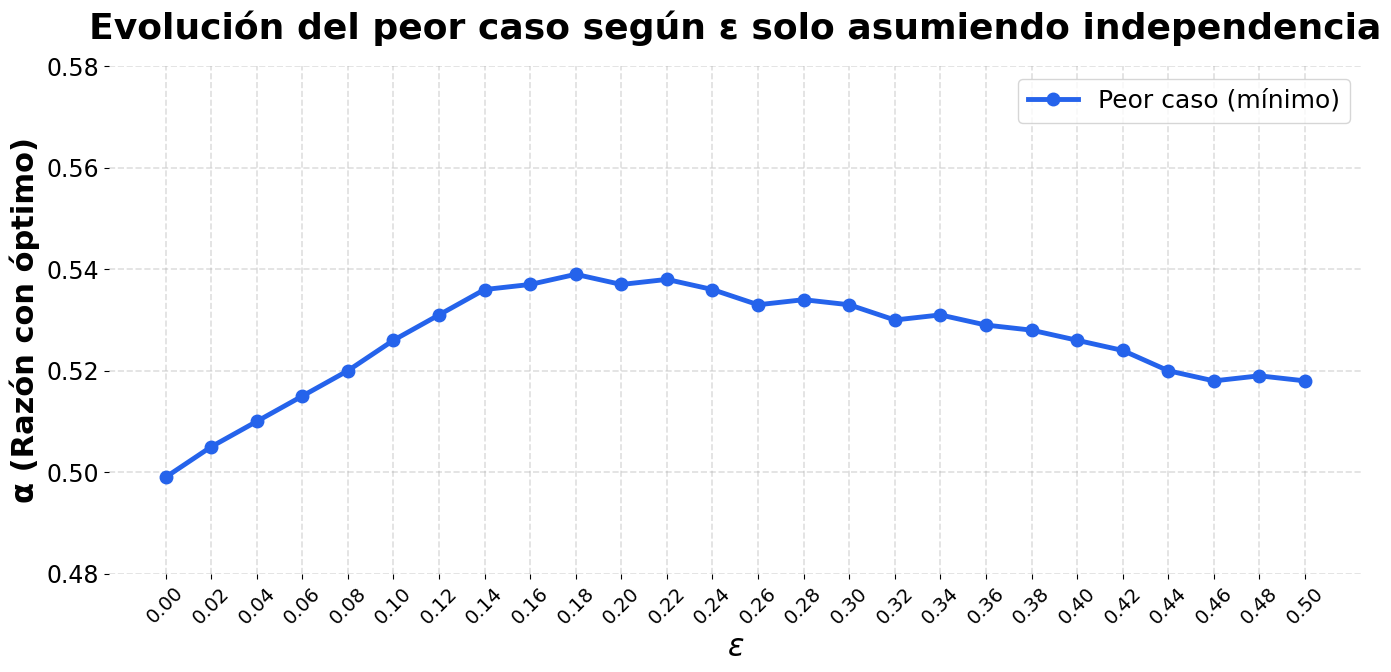

In [ ]:
#IA
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))

plt.plot(
    eps,
    peor_caso,
    marker='o',
    markersize=9,
    linewidth=3.5,
    color='#2563EB',
    label='Peor caso (mínimo)'
)

plt.xlabel(r'$\varepsilon$', fontsize=22, fontweight='bold')
plt.ylabel('α (Razón con óptimo)', fontsize=22, fontweight='bold')

plt.title(
    'Evolución del peor caso según ε solo asumiendo independencia',
    fontsize=26,
    fontweight='bold',
    pad=20
)

plt.xticks(eps, fontsize=14, rotation=45)
plt.yticks(fontsize=17)

plt.grid(True, linestyle='--', alpha=0.4, linewidth=1.2)

plt.ylim(0.48, 0.58)

plt.legend(fontsize=18, loc='best')

plt.tight_layout()

plt.savefig('peor_caso_presentacion.png', dpi=300, bbox_inches='tight')

plt.show()

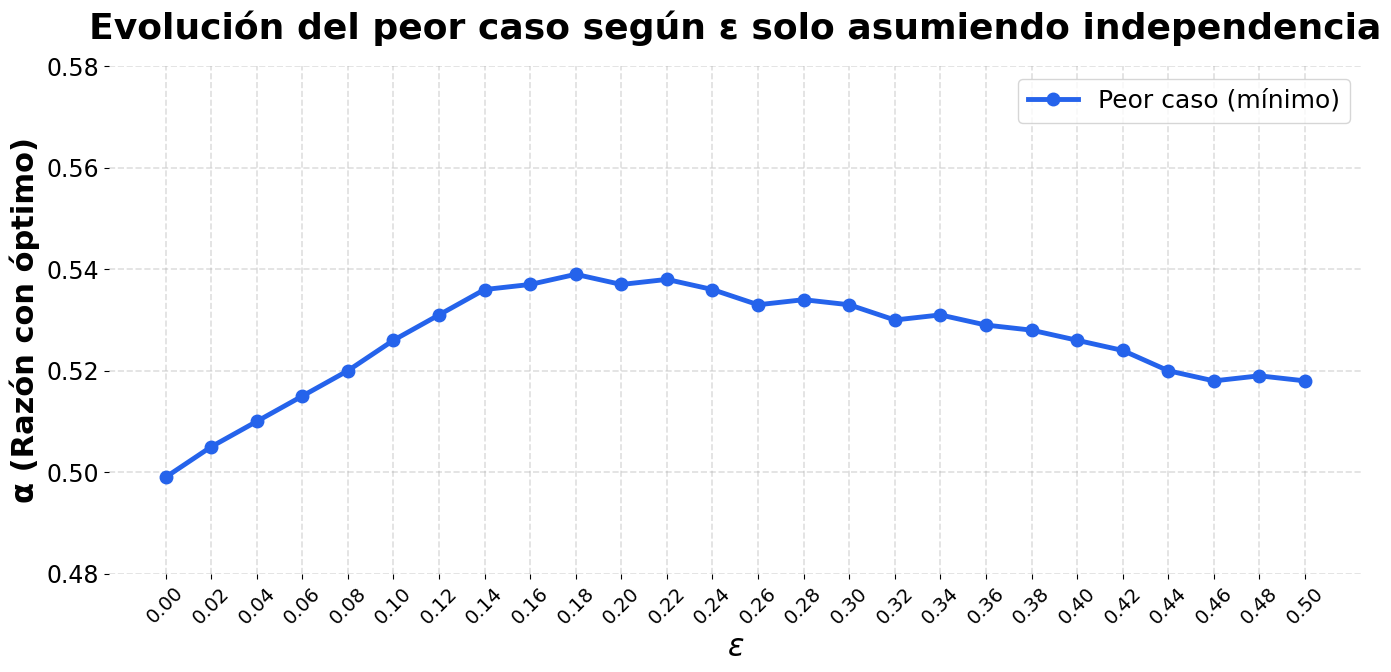

In [ ]:
#IA
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))

plt.plot(
    eps,
    peor_caso,
    marker='o',
    markersize=9,
    linewidth=3.5,
    color='#2563EB',
    label='Peor caso (mínimo)'
)

plt.xlabel(r'$\varepsilon$', fontsize=22, fontweight='bold')
plt.ylabel('α (Razón con óptimo)', fontsize=22, fontweight='bold')

plt.title(
    'Evolución del peor caso según ε solo asumiendo independencia',
    fontsize=26,
    fontweight='bold',
    pad=20
)

plt.xticks(eps, fontsize=14, rotation=45)
plt.yticks(fontsize=17)

plt.grid(True, linestyle='--', alpha=0.4, linewidth=1.2)

plt.ylim(0.48, 0.58)

plt.legend(fontsize=18, loc='best')

plt.tight_layout()

plt.savefig('peor_caso_presentacion.png', dpi=300, bbox_inches='tight')

plt.show()

Generando assets...
1 assets/g_n_rounds.gif
2 assets/greedy_trap.gif
3 assets/dual_certificate.png
4 assets/path3.gif
5 assets/rounding.gif
6 assets/correlation_prune.gif
7 assets/scoreboard.png


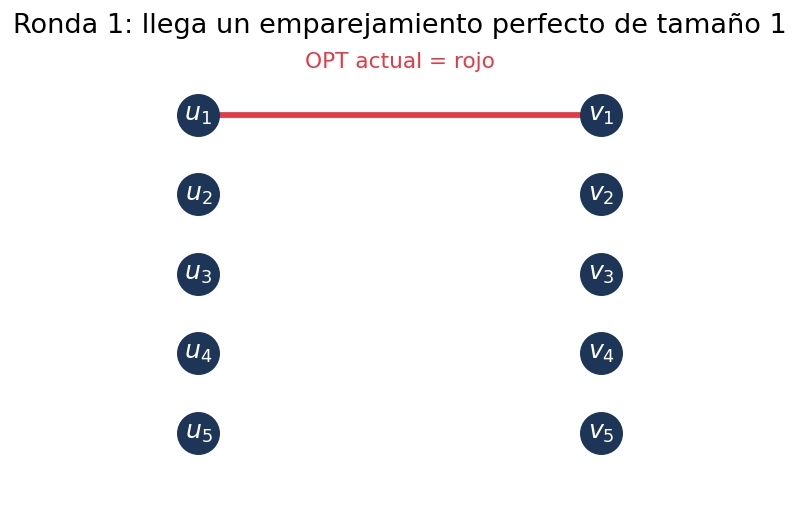

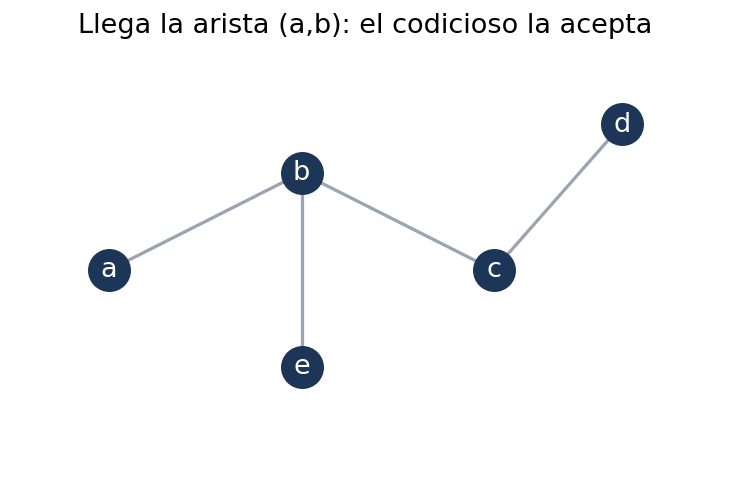

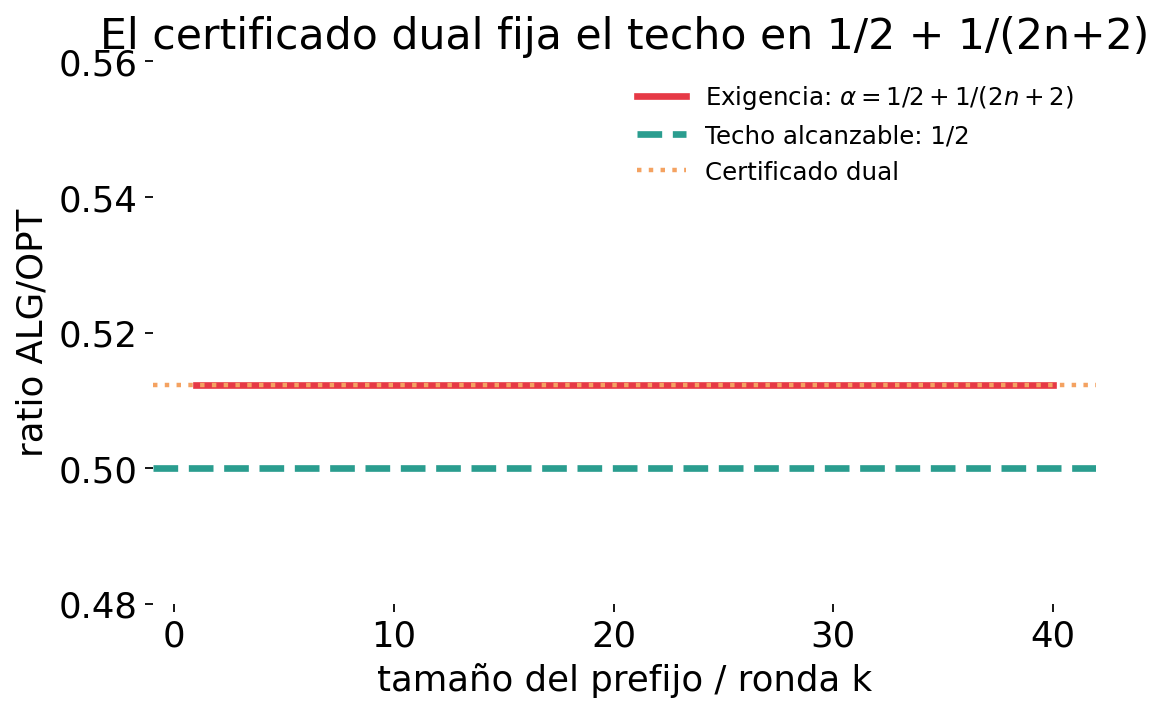

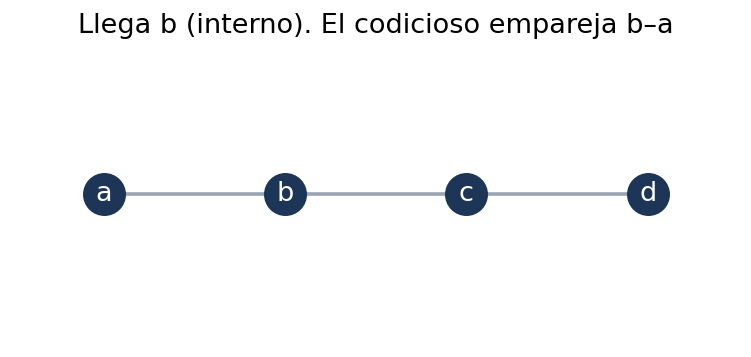

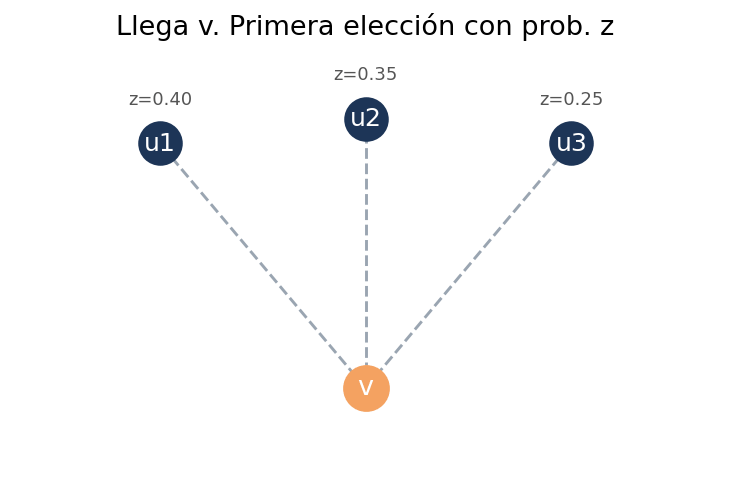

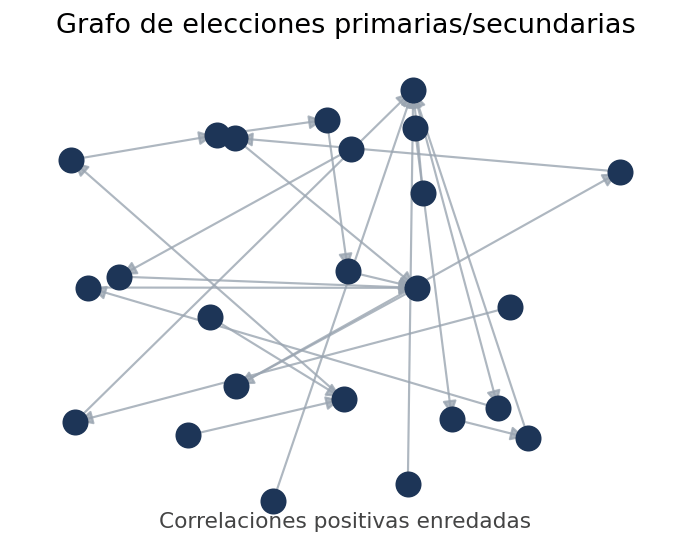

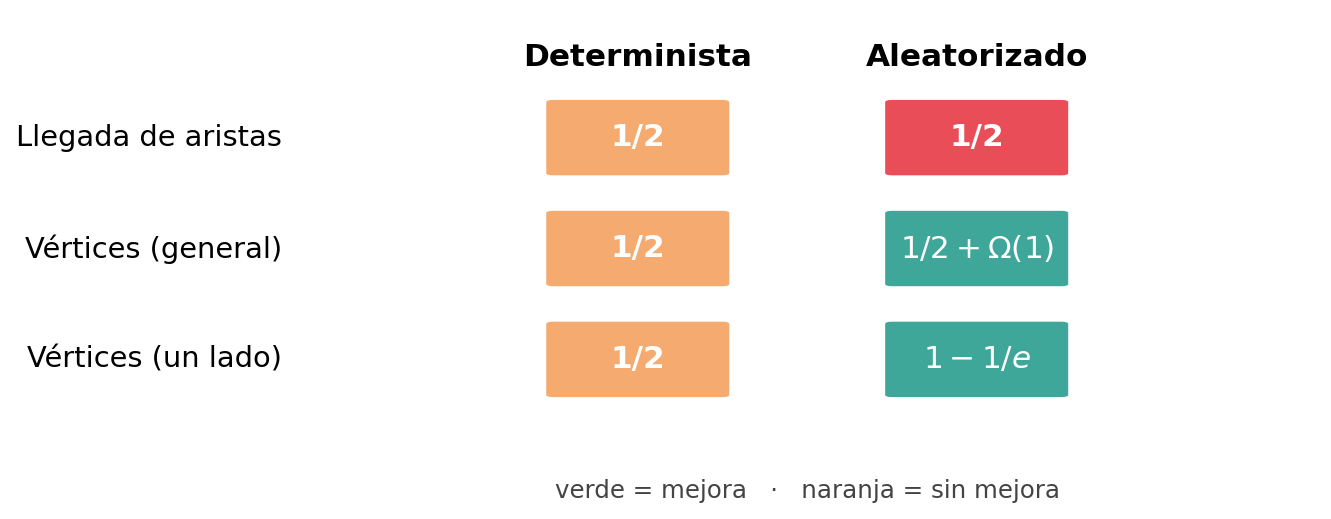

In [ ]:
#IA
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch
from PIL import Image
import io, os, random
from IPython.display import display, Image as IPyImage

OUT = "assets"
os.makedirs(OUT, exist_ok=True)

# ---------- global style ----------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 16,
    "axes.linewidth": 0,
    "figure.facecolor": "white",
})
C_EDGE   = "#9aa5b1"   # normal edge
C_OPT    = "#e63946"   # OPT edge (red)
C_MATCH  = "#2a9d8f"   # matched edge (teal)
C_DEAD   = "#d9d9d9"   # discarded
C_NODE   = "#1d3557"
C_ACCENT = "#f4a261"

def save_fig(fig, name, dpi=160):
    path = os.path.join(OUT, name)
    fig.savefig(path, dpi=dpi, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    return path

def frames_to_gif(frames, name, duration=900, loop=0):
    """frames: list of PIL Images"""
    path = os.path.join(OUT, name)
    frames[0].save(path, save_all=True, append_images=frames[1:],
                   duration=duration, loop=loop, optimize=True)
    return path

def fig_to_pil(fig, dpi=130):
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=dpi, bbox_inches="tight",
                facecolor="white")
    plt.close(fig)
    buf.seek(0)
    return Image.open(buf).convert("RGB")

# ============================================================
#  ASSET 1 — G_n : the hard edge-arrival instance
#  (Figure 1 of the paper, animated, Spanish captions)
# ============================================================
def asset1_gn(n=5):
    frames = []
    # positions: left column U, right column V
    Ux, Vx = 0.0, 3.0
    def pos_u(i): return (Ux, -(i-1)*1.0)      # i = 1..n
    def pos_v(i): return (Vx, -(i-1)*1.0)

    # which edges have arrived by end of round r:
    # round r reveals (u_j, v_{r-j+1}) for j=1..r
    def edges_after(r):
        s = set()
        for rr in range(1, r+1):
            for j in range(1, rr+1):
                s.add((j, rr-j+1))
        return s
    def opt_round(r):
        # unique perfect matching on first r: (u_j, v_{r-j+1})
        return {(j, r-j+1) for j in range(1, r+1)}

    for r in range(1, n+1):
        fig, ax = plt.subplots(figsize=(7.2, 4.6))
        ax.set_xlim(-1.2, 4.2); ax.set_ylim(-(n-1)-0.9, 0.9)
        ax.axis("off")
        # nodes
        for i in range(1, n+1):
            ax.scatter(*pos_u(i), s=520, c=C_NODE, zorder=3)
            ax.text(pos_u(i)[0], pos_u(i)[1], f"$u_{i}$", color="white",
                    ha="center", va="center", fontsize=14, zorder=4)
            ax.scatter(*pos_v(i), s=520, c=C_NODE, zorder=3)
            ax.text(pos_v(i)[0], pos_v(i)[1], f"$v_{i}$", color="white",
                    ha="center", va="center", fontsize=14, zorder=4)
        present = edges_after(r)
        opt = opt_round(r)
        # draw present edges
        for (j,k) in present:
            x1,y1 = pos_u(j); x2,y2 = pos_v(k)
            if (j,k) in opt:
                ax.plot([x1,x2],[y1,y2], color=C_OPT, lw=3.2, zorder=2)
            else:
                ax.plot([x1,x2],[y1,y2], color=C_EDGE, lw=1.6,
                        ls=(0,(4,3)), zorder=1)
        ax.set_title(f"Ronda {r}: llega un emparejamiento perfecto de tamaño {r}",
                     fontsize=15)
        # legend text (spoken, minimal)
        ax.text(1.5, 0.6, "OPT actual = rojo", color=C_OPT,
                fontsize=12, ha="center")
        frames.append(fig_to_pil(fig))
    return frames_to_gif(frames, "g_n_rounds.gif", duration=1100)

# ============================================================
#  ASSET 2 — greedy trap: a tiny graph where greedy locks in badly
# ============================================================
def asset2_greedy_trap():
    # Graph: center path a-b-c plus extra leaves that make greedy regret.
    # Arrival order chosen so greedy takes a bad first edge.
    # nodes
    P = {"a":(0,0), "b":(1.2,0.6), "c":(2.4,0), "d":(3.2,0.9), "e":(1.2,-0.6)}
    edges_order = [("a","b"), ("b","c"), ("c","d"), ("b","e")]
    frames=[]
    matched=set(); used=set(); dead=set()
    def draw(matched, used, dead, title, note=""):
        fig, ax = plt.subplots(figsize=(7.0,4.2)); ax.axis("off")
        ax.set_xlim(-0.6,3.8); ax.set_ylim(-1.2,1.4)
        # edges
        for (u,v) in edges_order:
            x1,y1=P[u]; x2,y2=P[v]
            if (u,v) in matched:
                col, lw, ls = C_MATCH, 3.4, "-"
            elif (u,v) in dead:
                col, lw, ls = C_DEAD, 1.8, (0,(3,3))
            else:
                col, lw, ls = C_EDGE, 1.8, "-"
            ax.plot([x1,x2],[y1,y2], color=col, lw=lw, ls=ls, zorder=1)
        for name,(x,y) in P.items():
            col = C_ACCENT if name in used else C_NODE
            ax.scatter(x,y,s=520,c=col,zorder=3)
            ax.text(x,y,name,color="white",ha="center",va="center",
                    fontsize=15,zorder=4)
        ax.set_title(title, fontsize=15)
        if note: ax.text(1.6,-1.0,note,ha="center",fontsize=12,color="#444")
        return fig_to_pil(fig)

    frames.append(draw(matched,used,dead,
        "Llega la arista (a,b): el codicioso la acepta"))
    matched.add(("a","b")); used |= {"a","b"}
    frames.append(draw(matched,used,dead,
        "Ahora (b,c) no se puede: b ya está emparejado",
        "Una elección temprana bloquea mejores aristas"))
    dead.add(("b","c")); dead.add(("b","e"))
    frames.append(draw(matched,used,dead,
        "(c,d) se acepta, pero (b,e) queda perdida",
        "Resultado: 2 aristas de 3 posibles"))
    return frames_to_gif(frames,"greedy_trap.gif",duration=1200)

# ============================================================
#  ASSET 3 — dual certificate picture (static PNG)
#  rising requirement alpha*k vs budget ceiling; gap -> 1/2
# ============================================================
def asset3_dual_certificate(n=40):
    k = np.arange(1, n+1)
    # requirement: alpha * k with alpha slightly > 1/2
    alpha = 0.5 + 1.0/(2*n+2)
    req = alpha * k
    # budget ceiling implied by dual: sum_j (l_j+r_j) = 1/2 + 1/(2n+2)
    ceiling = np.full_like(k, 0.5 + 1.0/(2*n+2), dtype=float)
    # scaled visual: show ratio bound as horizontal line
    fig, ax = plt.subplots(figsize=(7.6,4.4))
    ax.plot(k, req/k, color=C_OPT, lw=3,
            label=r"Exigencia: $\alpha = 1/2 + 1/(2n+2)$")
    ax.axhline(0.5, color=C_MATCH, lw=3, ls="--",
               label="Techo alcanzable: 1/2")
    ax.axhline(0.5 + 1.0/(2*n+2), color=C_ACCENT, lw=2, ls=":",
               label="Certificado dual")
    ax.set_ylim(0.48, 0.56)
    ax.set_xlabel("tamaño del prefijo / ronda k")
    ax.set_ylabel("ratio ALG/OPT")
    ax.set_title("El certificado dual fija el techo en 1/2 + 1/(2n+2)")
    ax.legend(loc="upper right", fontsize=11, frameon=False)
    for s in ["top","right"]: ax.spines[s].set_visible(False)
    return save_fig(fig,"dual_certificate.png")

# ============================================================
#  ASSET 4 — path-on-3, internal vertices first (separating instance)
# ============================================================
def asset4_path3():
    P = {"a":(0,0), "b":(1.2,0), "c":(2.4,0), "d":(3.6,0)}
    order = ["b","c","a","d"]   # internal first
    edges = [("a","b"),("b","c"),("c","d")]
    frames=[]
    matched=set(); used=set(); dead=set()
    def draw(title, note=""):
        fig, ax = plt.subplots(figsize=(7.2,3.0)); ax.axis("off")
        ax.set_xlim(-0.6,4.2); ax.set_ylim(-1.0,1.0)
        for (u,v) in edges:
            x1,y1=P[u]; x2,y2=P[v]
            if (u,v) in matched: col,lw,ls=C_MATCH,3.6,"-"
            elif (u,v) in dead:  col,lw,ls=C_DEAD,2.0,(0,(3,3))
            else:                col,lw,ls=C_EDGE,2.0,"-"
            ax.plot([x1,x2],[y1,y2],color=col,lw=lw,ls=ls,zorder=1)
        for name,(x,y) in P.items():
            col = C_ACCENT if name in used else C_NODE
            ax.scatter(x,y,s=520,c=col,zorder=3)
            ax.text(x,y,name,color="white",ha="center",va="center",
                    fontsize=15,zorder=4)
        ax.set_title(title,fontsize=15)
        if note: ax.text(1.8,-0.85,note,ha="center",fontsize=12,color="#444")
        return fig_to_pil(fig)

    frames.append(draw("Llega b (interno). El codicioso empareja b–a"))
    matched.add(("a","b")); used|={"a","b"}
    frames.append(draw("Llega c (interno). c no tiene vecino libre",
                       "El codicioso se queda atascado"))
    dead.add(("b","c"))
    frames.append(draw("Llegan a y d. Nada que hacer: b y c ya están usados",
                       "OPT = 2 aristas; codicioso = 1  ->  ratio 1/2"))
    dead.add(("c","d"))
    return frames_to_gif(frames,"path3.gif",duration=1300)

# ============================================================
#  ASSET 5 — rounding: first choice / second choice (the core idea)
# ============================================================
def asset5_rounding():
    # arriving vertex v with 3 neighbours
    v = (2.0, -1.6)
    neigh = {"u1":(0.6,0.4),"u2":(2.0,0.6),"u3":(3.4,0.4)}
    z = {"u1":0.4,"u2":0.35,"u3":0.25}
    frames=[]
    def draw(pick1=None, pick2=None, title="", note="", hit=None):
        fig, ax = plt.subplots(figsize=(7.0,4.4)); ax.axis("off")
        ax.set_xlim(-0.4,4.4); ax.set_ylim(-2.4,1.2)
        for name,(x,y) in neigh.items():
            ax.plot([v[0],x],[v[1],y],color=C_EDGE,lw=1.6,ls="--",zorder=1)
        ax.scatter(*v,s=620,c=C_ACCENT,zorder=3)
        ax.text(*v,"v",color="white",ha="center",va="center",
                fontsize=15,zorder=4)
        for name,(x,y) in neigh.items():
            ax.scatter(x,y,s=560,c=C_NODE,zorder=3)
            ax.text(x,y,name.replace("u","$u_{")+"$" if False else name,
                    color="white",ha="center",va="center",fontsize=14,zorder=4)
            ax.text(x,y+0.32,f"z={z[name]:.2f}",ha="center",fontsize=10,
                    color="#555")
        if pick1:
            x,y=neigh[pick1]
            ax.annotate("", xy=(x,y), xytext=v,
                        arrowprops=dict(arrowstyle="-|>",color=C_OPT,lw=3))
        if pick2:
            x,y=neigh[pick2]
            ax.annotate("", xy=(x,y), xytext=v,
                        arrowprops=dict(arrowstyle="-|>",color=C_MATCH,lw=3,
                                        ls="--"))
        ax.set_title(title,fontsize=15)
        if note: ax.text(2.0,-2.2,note,ha="center",fontsize=12,color="#444")
        return fig_to_pil(fig)

    frames.append(draw(title="Llega v. Primera elección con prob. z"))
    frames.append(draw(pick1="u2", title="Intenta u2 ... pero u2 ya está ocupado",
                       note="La primera elección falla"))
    frames.append(draw(pick1="u2", pick2="u1",
                       title="Con prob. √ε hace una SEGUNDA elección: u1",
                       note="La segunda elección rescata el emparejamiento"))
    frames.append(draw(pick1="u2", pick2="u1", hit="u1",
                       title="u1 está libre: v–u1 se empareja",
                       note="Así se recupera la pérdida de la normalización"))
    return frames_to_gif(frames,"rounding.gif",duration=1400)

# ============================================================
#  ASSET 6 — correlation pruning: tangle -> small components
# ============================================================
def asset6_correlation_prune(seed=7):
    rng = np.random.default_rng(seed)
    n = 24
    # random points
    pts = rng.uniform(0,1,(n,2))
    # random directed choices (primary)
    prim = [(i, rng.integers(0,n)) for i in range(n)]
    frames=[]
    def draw(edges, title, note=""):
        fig, ax = plt.subplots(figsize=(6.6,5.0)); ax.axis("off")
        ax.set_xlim(-0.1,1.1); ax.set_ylim(-0.1,1.1)
        for (i,j) in edges:
            ax.annotate("", xy=pts[j], xytext=pts[i],
                        arrowprops=dict(arrowstyle="-|>",color=C_EDGE,lw=1.2,
                                        alpha=0.8))
        ax.scatter(pts[:,0],pts[:,1],s=180,c=C_NODE,zorder=3)
        ax.set_title(title,fontsize=15)
        if note: ax.text(0.5,-0.06,note,ha="center",fontsize=12,color="#444")
        return fig_to_pil(fig)

    frames.append(draw(prim,"Grafo de elecciones primarias/secundarias",
                       "Correlaciones positivas enredadas"))
    # prune: keep only edges whose endpoints are mutually close
    keep=[]
    for (i,j) in prim:
        if np.linalg.norm(pts[i]-pts[j]) < 0.35:
            keep.append((i,j))
    frames.append(draw(keep,"Tras podar: la mayoría cae en componentes pequeñas",
                       "Componentes pequeñas ⇒ correlación débil"))
    # highlight tiny components
    return frames_to_gif(frames,"correlation_prune.gif",duration=1500)

# ============================================================
#  ASSET 7 — scoreboard (static, colored, minimal text)
# ============================================================
def asset7_scoreboard():
    fig, ax = plt.subplots(figsize=(8.2,3.6)); ax.axis("off")
    cols = ["Determinista","Aleatorizado"]
    rows = ["Llegada de aristas","Vértices (general)","Vértices (un lado)"]
    vals = [["1/2","1/2"],["1/2",r"$1/2+\Omega(1)$"],["1/2",r"$1-1/e$"]]
    color = [["#f4a261","#e63946"],["#f4a261","#2a9d8f"],["#f4a261","#2a9d8f"]]
    ax.set_xlim(0,3); ax.set_ylim(0,4)
    for c,lab in enumerate(cols):
        ax.text(1.0+c*1.0,3.55,lab,ha="center",fontsize=14,weight="bold")
    for r,lab in enumerate(rows):
        y = 2.9 - r*1.0
        ax.text(-0.05,y,lab,ha="right",va="center",fontsize=13)
        for c in range(2):
            ax.add_patch(mpatches.FancyBboxPatch((0.75+c*1.0,y-0.32),
                         0.5,0.64,boxstyle="round,pad=0.02",
                         fc=color[r][c],ec="none",alpha=0.9))
            ax.text(1.0+c*1.0,y,vals[r][c],ha="center",va="center",
                    fontsize=14,color="white",weight="bold")
    ax.text(1.5,-0.35,"verde = mejora   ·   naranja = sin mejora",
            ha="center",fontsize=11,color="#444")
    return save_fig(fig,"scoreboard.png")

# ============================================================
#  BUILD EVERYTHING
# ============================================================
if __name__ == "__main__":
    print("Generando assets...")
    p1 = asset1_gn(5);            print("1", p1)
    p2 = asset2_greedy_trap();    print("2", p2)
    p3 = asset3_dual_certificate();print("3", p3)
    p4 = asset4_path3();          print("4", p4)
    p5 = asset5_rounding();       print("5", p5)
    p6 = asset6_correlation_prune();print("6", p6)
    p7 = asset7_scoreboard();     print("7", p7)

    # display inline (Colab)
    for p in [p1,p2,p3,p4,p5,p6,p7]:
        if p.endswith(".gif"):
            display(IPyImage(filename=p))
        else:
            display(IPyImage(filename=p))


In [ ]:
import numpy as np
import scipy.optimize as opt
import matplotlib.pyplot as plt
from scipy.optimize import brentq

In [ ]:
#sin IA

#algoritmo 1,
def ALG1(VecinosVs,beta,k):
  y = np.zeros(len(VecinosVs))#los y_v
  x = np.zeros((len(VecinosVs),len(VecinosVs)))#lso xuv
  for i in range(len(VecinosVs)): #para cada vertice
    Yvecinos=[y[u] for u in VecinosVs[i]]#tomamos los y de los vecinos
    Theta=ThetaOptimo(Yvecinos,k)#sacamos theta
    for j in VecinosVs[i]:#para cada vecino
      x[i][j]= (max(0,Theta-y[j])/beta)*(1+(1-Theta)/(fk(Theta,k)))#calc xuv
      x[j][i]=x[i][j]#pues matriz
      y[j]=max(Theta,y[j])#reajustamos yu vecinos
    y[i]=1-Theta#reajustamos yv vertice
  return y,x


In [ ]:
#IA revisión
#fucnion de fk(theta), beta*, theta

def fk(theta,k):
  return ((((1+k)/2)-theta)**((1+k)/(2*k)))*((((k-1)/2)+theta)**((k-1)/(2*k)))

#funcion que entrega el theta del problema a resolver en alg1 (igual se usa en alg 3)

#funcion full claude
def ThetaOptimo(vecinos,k):
    if len(vecinos)==0:
        return 1.0#evaluar esto, caso vacio
    vecinos=np.asarray(vecinos,dtype=float)
    g=lambda th: np.sum(np.maximum(0.0,th-vecinos))-fk(th,k)
    if g(1.0)<=0:
        return 1.0
    return brentq(g,0.0,1.0,xtol=1e-14)

#funcion que comprueba si un vertice ya esta matcheado, los -1 es cuando no se eliguio uno, por lo tanto no se les puede elegir
def libre(indice,matching):
  if indice==-1:
    return False
  for i in range(len(matching)):
    if matching[i][indice]==1:
      return False
  return True

#correccion que me dio deepseek
def ElegirIndice(vecinos, probs):
    """Muestreo manual. Si sum(probs) < 1, devuelve -1 con la masa restante."""
    probs = np.asarray(probs, dtype=float)
    r = np.random.random()
    cum = 0.0
    for u, p in zip(vecinos, probs):
        cum += p
        if r < cum:
            return u
    return -1



def ALG3(VecinosVs,epsilon):
  beta,k=2-epsilon,1+2*epsilon
  y = np.zeros(len(VecinosVs))#los y_v
  x = np.zeros((len(VecinosVs),len(VecinosVs)))#lso xuv
  M=np.zeros((len(VecinosVs),len(VecinosVs)))
  p_emp=np.zeros(len(VecinosVs)) #claude
  for i in range(len(VecinosVs)): #para cada vertice
    Yvecinos=[y[u] for u in VecinosVs[i]]#tomamos los y de los vecinos
    Theta=ThetaOptimo(Yvecinos,k)#sacamos theta
    for j in VecinosVs[i]:#para cada vecino
      x[i][j]= (max(0,Theta-y[j])/beta)*(1+(1-Theta)/(fk(Theta,k)))#calc xuv
      x[j][i]=x[i][j]#pues matriz
      y[j]=max(Theta,y[j])#reajustamos yu vecinos
    y[i]=1-Theta#reajustamos yv vertice
    Pr_de={u: min(1.0,max(1e-9,1-p_emp[u])) for u in VecinosVs[i]} #claude
    z=np.zeros(len(VecinosVs))
    znormal=np.zeros(len(VecinosVs))
    for j in VecinosVs[i]:
      Pr=Pr_de[j]#sacar proba segun 3.3 #claude
      z[j]=x[i][j]/Pr
    for j in VecinosVs[i]:
      znormal[j]=z[j]/max(1,np.sum(z))
    vec=VecinosVs[i] #claude
    z_de={u: x[i][u]/Pr_de[u] for u in vec} #claude
    suma_z=sum(z_de.values()) #claude
    zn_de={u: z_de[u]/max(1,suma_z) for u in vec} #claude
    ProbDrop_de={} #claude
    prob_arista={} #claude
    for u in vec: #claude
      primero=Pr_de[u]*zn_de[u] #claude
      if suma_z>1: #claude
        S=sum(zn_de[w]*(1-Pr_de[w]) for w in vec if w!=u) #claude (en est e caso vemos que se asume independiencia, difiere un poco de la 7)
        segundo=primero*np.sqrt(epsilon)*S #claude
        keep=1.0 if segundo<=0 else min(1.0,max(0.0,(x[i][u]-primero)/segundo)) #claude
        ProbDrop_de[u]=1-keep #claude
        prob_arista[u]=primero+keep*segundo #claude
      else: #claude
        ProbDrop_de[u]=0.0 #claude
        prob_arista[u]=primero #claude
    for u in vec: #claude
      p_emp[u]+=prob_arista[u] #claude
    p_emp[i]=sum(prob_arista.values()) #claude
    elegido1=ElegirIndice(VecinosVs[i],znormal[VecinosVs[i]])##claude corrigio la toma de znormal[VecinosVs[i]]
    elegido2=-1
    if np.sum(z)>1:
      if np.random.uniform(0,1)<=np.sqrt(epsilon):
        elegido2=ElegirIndice(VecinosVs[i],znormal[VecinosVs[i]])#claude corrigio la toma de znormal[VecinosVs[i]]
        ProbDropping=ProbDrop_de.get(elegido2,1)#sacar proba segu8n 7} #claude
        if np.random.uniform(0,1)<=ProbDropping:
          elegido2=-1
    if libre(elegido1,M):
      M[i][elegido1]=1
      M[elegido1][i]=1
    elif libre(elegido2,M):
      M[i][elegido2]=1
      M[elegido2][i]=1
  return M

In [ ]:
# IA
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter


# ---------------------------------------------------------------------
# Helpers para extraer info del matching devuelto por ALG3
# ---------------------------------------------------------------------
def tam_matching(M):
    """Tamano del matching a partir de la matriz simetrica M."""
    return int(round(M.sum() / 2))


def aristas_de_M(M):
    """Devuelve lista de (u,v) con u<v a partir de la matriz M."""
    n = M.shape[0]
    return [(u, v) for v in range(n) for u in range(v) if M[v][u] == 1]


# ---------------------------------------------------------------------
# Conversiones grafo <-> vecinos
# ---------------------------------------------------------------------
def a_grafo(vecinos):
    G = nx.Graph()
    G.add_nodes_from(range(len(vecinos)))
    for v, vec in enumerate(vecinos):
        G.add_edges_from((u, v) for u in vec)
    return G


def a_matriz(vecinos):
    n = len(vecinos)
    A = np.zeros((n, n), dtype=int)
    for v, vec in enumerate(vecinos):
        for u in vec:
            A[u][v] = A[v][u] = 1
    return A


def desde_matriz(A, orden=None):
    n = len(A)
    orden = list(range(n)) if orden is None else list(orden)
    pos = {v: k for k, v in enumerate(orden)}
    return [[pos[u] for u in orden[:k] if A[orden[k]][u]] for k in range(n)]


# ---------------------------------------------------------------------
# Matching optimo (Edmonds / blossom) y baselines
# ---------------------------------------------------------------------
def matching_optimo(vecinos):
    G = a_grafo(vecinos)
    M = nx.max_weight_matching(G, maxcardinality=True)
    pares = sorted((min(a, b), max(a, b)) for a, b in M)
    return len(pares), pares


def matching_optimo_aristas(vecinos):
    _, pares = matching_optimo(vecinos)
    return set(pares)


def greedy_det(vecinos):
    usado, M = set(), []
    for v, vec in enumerate(vecinos):
        for u in vec:
            if u not in usado:
                M.append((u, v)); usado |= {u, v}
                break
    return M


def greedy_aleatorio(vecinos, rng):
    usado, M = set(), []
    for v, vec in enumerate(vecinos):
        libres = [u for u in vec if u not in usado]
        if libres:
            u = libres[rng.integers(len(libres))]
            M.append((u, v)); usado |= {u, v}
    return M


# ---------------------------------------------------------------------
# Generadores de instancias
# ---------------------------------------------------------------------
def camino_dificil(copias):
    V = []
    for i in range(copias):
        base = 4 * i
        V += [[], [base], [base], [base + 1]]
    return V


def triangular_superior(m):
    V = [[] for _ in range(m)]
    for t in range(m):
        V.append(list(range(m - 1, t - 1, -1)))
    return V


def bipartito_completo(m):
    return [[] for _ in range(m)] + [list(range(m)) for _ in range(m)]


def completo(n):
    return [list(range(v)) for v in range(n)]


def erdos_renyi(n, p, seed=0):
    r = np.random.default_rng(seed)
    return [[u for u in range(v) if r.random() < p] for v in range(n)]


def regular_aleatorio(n, d, seed=0):
    G = nx.random_regular_graph(d, n, seed=seed)
    A = nx.to_numpy_array(G, dtype=int)
    orden = np.random.default_rng(seed).permutation(n)
    return desde_matriz(A, orden)


def arbol_aleatorio(n, seed=0):
    r = np.random.default_rng(seed)
    A = np.zeros((n, n), dtype=int)
    for v in range(1, n):
        u = r.integers(v)
        A[u][v] = A[v][u] = 1
    return desde_matriz(A, r.permutation(n))


def ciclo(n, seed=0):
    A = np.zeros((n, n), dtype=int)
    for v in range(n):
        A[v][(v + 1) % n] = A[(v + 1) % n][v] = 1
    return desde_matriz(A, np.random.default_rng(seed).permutation(n))


def instancias_estandar():
    return {
        "camino dificil x30": camino_dificil(30),
        "triangular sup. m=30": triangular_superior(30),
        "K_{20,20}": bipartito_completo(20),
        "completo n=30": completo(30),
        "ciclo n=60": ciclo(60),
        "arbol n=80": arbol_aleatorio(80, seed=1),
        "regular d=3 n=60": regular_aleatorio(60, 3, seed=1),
        "regular d=10 n=60": regular_aleatorio(60, 10, seed=1),
        "ER n=60 p=0.05": erdos_renyi(60, 0.05, seed=1),
        "ER n=60 p=0.2": erdos_renyi(60, 0.2, seed=1),
        "ER n=80 p=0.5": erdos_renyi(80, 0.5, seed=1),
    }


# ---------------------------------------------------------------------
# Comparacion (usa ALG3 directamente)
# ---------------------------------------------------------------------
def comparar(vecinos, eps_lista=(0.0,0.02,0.04,0.06,0.08,0.1,0.12,0.14,0.16,0.18,0.2,0.22,0.24,0.26,0.28,0.3,0.32,0.34,0.36,0.38,0.4,0.42,0.44,0.46,0.48,0.5),
             N=2000, seed=0, rep_greedy=300):
    opt, _ = matching_optimo(vecinos)
    rng = np.random.default_rng(seed)
    fila = {
        "n": len(vecinos),
        "OPT": opt,
        "greedy_det": len(greedy_det(vecinos)) / opt,
        "greedy_alea": np.mean(
            [len(greedy_aleatorio(vecinos, rng)) for _ in range(rep_greedy)]
        ) / opt,
    }
    for eps in eps_lista:
        np.random.seed(seed)   # reproducibilidad
        tamanos = np.array([tam_matching(ALG3(vecinos, eps))
                            for _ in range(N)])
        fila[eps] = {
            "ratio": tamanos.mean() / opt,
            "se": tamanos.std() / np.sqrt(N) / opt,
        }
    return fila


def tabla(instancias=None, eps_lista=(0.0,0.02,0.04,0.06,0.08,0.1,0.12,0.14,0.16,0.18,0.2,0.22,0.24,0.26,0.28,0.3,0.32,0.34,0.36,0.38,0.4,0.42,0.44,0.46,0.48,0.5), N=2000, seed=0):
    instancias = instancias_estandar() if instancias is None else instancias
    filas = {nombre: comparar(V, eps_lista, N, seed)
             for nombre, V in instancias.items()}

    cols = ["greedy_det", "greedy_alea"] + [f"eps={e}" for e in eps_lista]
    print(f"{'instancia':24s}{'n':>4s}{'OPT':>5s}"
          + "".join(f"{c:>14s}" for c in cols)
          + "   (razon = E|M|/OPT)")

    valores = {c: [] for c in cols}
    for nombre, f in filas.items():
        vals = ([f["greedy_det"], f["greedy_alea"]]
                + [f[e]["ratio"] for e in eps_lista])
        for c, v in zip(cols, vals):
            valores[c].append(v)
        print(f"{nombre:24s}{f['n']:4d}{f['OPT']:5d}"
              + "".join(f"{v:14.3f}" for v in vals))

    print("-" * (33 + 14 * len(cols)))
    print(f"{'promedio':33s}"
          + "".join(f"{np.mean(valores[c]):14.3f}" for c in cols))
    print(f"{'PEOR CASO (minimo)':33s}"
          + "".join(f"{np.min(valores[c]):14.3f}" for c in cols))
    return filas


# ---------------------------------------------------------------------
# Animacion (usa ALG3 para extraer una trayectoria)
# ---------------------------------------------------------------------
def animar_comparacion(vecinos, eps=0.08, seed=0,
                       path="comparacion.gif", fps=2, dpi=80):
    n = len(vecinos)
    G = a_grafo(vecinos)
    pos = nx.spring_layout(G, seed=42)

    np.random.seed(seed)
    M = ALG3(vecinos, eps)
    aristas_M = set(aristas_de_M(M))

    # Para cada v, saber con quien se emparejo (si acaso) en esta corrida
    emparejado_con = [None] * n
    for (u, v) in aristas_M:
        emparejado_con[v] = u

    opt_edges = matching_optimo_aristas(vecinos)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))

    def dibujar(ax, titulo, llegados, match_edges):
        ax.clear()
        ax.set_title(titulo, fontsize=11)
        colores = ['tab:blue' if i in llegados else 'lightgray'
                   for i in range(n)]
        nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colores,
                               node_size=250, edgecolors='black',
                               linewidths=0.5)
        nx.draw_networkx_labels(G, pos, ax=ax, font_size=8)
        visibles = [(u, v) for (u, v) in G.edges()
                    if u in llegados and v in llegados]
        nx.draw_networkx_edges(G, pos, ax=ax, edgelist=visibles,
                               edge_color='lightgray', width=1)
        if match_edges:
            nx.draw_networkx_edges(G, pos, ax=ax,
                                   edgelist=list(match_edges),
                                   edge_color='red', width=3)
        ax.axis('off')

    def update(t):
        llegados = set(range(t + 1))

        # Online: aristas asignadas a vertices v <= t
        online_acum = [e for e in aristas_M if e[1] <= t]

        # OPT revelado: aristas con ambos extremos ya llegados
        opt_rev = set((a, b) for (a, b) in opt_edges if a <= t and b <= t)

        dibujar(ax1,
                f"Online ALG3 (eps={eps})\n|M| = {len(online_acum)}",
                llegados, online_acum)
        dibujar(ax2,
                f"OPT revelado paso a paso\n|M| = {len(opt_rev)}",
                llegados, opt_rev)
        return []

    anim = FuncAnimation(fig, update, frames=n,
                         interval=int(1000 / fps), blit=False)

    if path.endswith(".mp4"):
        from matplotlib.animation import FFMpegWriter
        anim.save(path, writer=FFMpegWriter(fps=fps), dpi=dpi)
    else:
        anim.save(path, writer=PillowWriter(fps=fps), dpi=dpi)
    plt.close(fig)
    print(f"Guardado: {path}")
    return path


# =====================================================================
# MAIN
# =====================================================================
if __name__ == "__main__":
    import time
    from pprint import pprint

    # 1) Tabla comparativa
    t0 = time.time()
    filas = tabla(N=2000, seed=0)
    print(f"\nTiempo tabla: {time.time() - t0:.1f}s")

    # 2) Animaciones
    V = camino_dificil(3)
    animar_comparacion(V, eps=0.08, seed=0, path="camino.gif", fps=1.5)

    V2 = erdos_renyi(15, 0.3, seed=3)
    animar_comparacion(V2, eps=0.0,  seed=0, path="er_alg2.gif", fps=2)
    animar_comparacion(V2, eps=0.08, seed=0, path="er_alg3.gif", fps=2)

    # 3) Extras
    pprint(comparar(erdos_renyi(60, 0.2, seed=1),
                    eps_lista=(0.0, 0.05), N=2000, seed=0))

    instancias_propias = {
        "camino dificil x10": camino_dificil(10),
        "K_{10,10}": bipartito_completo(10),
        "ER n=40 p=0.3": erdos_renyi(40, 0.3, seed=7),
    }
    tabla(instancias=instancias_propias,
          eps_lista=(0.0,0.02,0.04,0.06,0.08,0.1,0.12,0.14,0.16,0.18,0.2,0.22,0.24,0.26,0.28,0.3,0.32,0.34,0.36,0.38,0.4,0.42,0.44,0.46,0.48,0.5),
          N=2000, seed=0)

In [ ]:
#IA
def asset5_rounding():
    import matplotlib.pyplot as plt
    import os

    # --------------------------------------------------
    # Datos ilustrativos
    # --------------------------------------------------
    v = (2.0, -1.7)

    neigh = {
        "u1": (0.5, 0.4),
        "u2": (2.0, 0.6),
        "u3": (3.5, 0.4)
    }

    # Probabilidades originales
    z = {"u1": 0.60, "u2": 0.50, "u3": 0.40}

    # Normalización: suma original = 1.50
    total = sum(z.values())
    zp = {u: z[u] / max(1, total) for u in z}

    epsilon = 0.16
    second_prob = epsilon ** 0.5

    os.makedirs("imagenes_alg3", exist_ok=True)

    # --------------------------------------------------
    # Función de dibujo
    # --------------------------------------------------
    def draw(title, note="", pick1=None, pick2=None,
             occupied=None, matched=None, dropped=False,
             show_normalized=False, show_second=False):

        fig, ax = plt.subplots(figsize=(8, 5))
        ax.axis("off")
        ax.set_xlim(-0.5, 4.5)
        ax.set_ylim(-2.5, 1.5)

        # Aristas posibles
        for name, (x, y) in neigh.items():
            ax.plot(
                [v[0], x], [v[1], y],
                color=C_EDGE, lw=1.8, ls="--", zorder=1
            )

        # Vértice que llega
        ax.scatter(*v, s=700, c=C_ACCENT, zorder=3)
        ax.text(*v, "v", color="white", ha="center",
                va="center", fontsize=16, zorder=4)

        # Vecinos
        for name, (x, y) in neigh.items():

            color = C_NODE

            if occupied == name:
                color = "#999999"

            if matched == name:
                color = C_MATCH

            ax.scatter(x, y, s=600, c=color, zorder=3)

            ax.text(x, y, name, color="white",
                    ha="center", va="center",
                    fontsize=14, zorder=4)

            if show_normalized:
                label = f"z'={zp[name]:.2f}"
            else:
                label = f"z={z[name]:.2f}"

            ax.text(x, y + 0.38, label,
                    ha="center", fontsize=11, color="#444")

        # Primera elección
        if pick1:
            x, y = neigh[pick1]
            ax.annotate(
                "", xy=(x, y), xytext=v,
                arrowprops=dict(
                    arrowstyle="-|>", color=C_OPT, lw=3
                )
            )

        # Segunda elección
        if pick2:
            x, y = neigh[pick2]
            ax.annotate(
                "", xy=(x, y), xytext=v,
                arrowprops=dict(
                    arrowstyle="-|>", color=C_MATCH,
                    lw=3, ls="--"
                )
            )

        # Texto explicativo
        ax.set_title(title, fontsize=15, pad=15)

        if note:
            ax.text(
                2.0, -2.25, note,
                ha="center", fontsize=11,
                color="#444", wrap=True
            )

        # Leyenda
        ax.text(
            0.0, 1.25,
            "Primera elección: línea continua",
            fontsize=9, color=C_OPT
        )

        ax.text(
            2.5, 1.25,
            "Segunda elección: línea discontinua",
            fontsize=9, color=C_MATCH
        )

        fig.tight_layout()
        return fig

    # --------------------------------------------------
    # 1. Llegada del vértice
    # --------------------------------------------------
    fig1 = draw(
        "1. Llega el vértice v",
        note="Cada vecino tiene una probabilidad z_u de ser elegido."
    )

    # --------------------------------------------------
    # 2. Normalización
    # --------------------------------------------------
    fig2 = draw(
        "2. Normalización de probabilidades",
        note=(
            f"Como suma(z) = {total:.2f} > 1, "
            "se normalizan los valores.\n"
            "Ahora suma(z') = 1."
        ),
        show_normalized=True
    )

    # --------------------------------------------------
    # 3. Primera elección
    # --------------------------------------------------
    fig3 = draw(
        "3. Primera elección aleatoria",
        note="Se selecciona un vecino según las probabilidades z'.",
        pick1="u2",
        occupied="u2",
        show_normalized=True
    )

    # --------------------------------------------------
    # 4. Segunda elección
    # --------------------------------------------------
    fig4 = draw(
        "4. Segunda elección con probabilidad √ε",
        note=(
            f"Con probabilidad √ε = {second_prob:.2f}, "
            "se intenta una segunda elección.\n"
            "La selección usa probabilidades proporcionales a (z')²."
        ),
        pick1="u2",
        pick2="u1",
        occupied="u2",
        show_normalized=True,
        show_second=True
    )

    # --------------------------------------------------
    # 5. Descarte probabilístico
    # --------------------------------------------------
    fig5 = draw(
        "5. Control de la probabilidad de emparejamiento",
        note=(
            "La segunda elección puede descartarse aleatoriamente.\n"
            "Esto evita que una arista supere su valor fraccionario x_uv."
        ),
        pick1="u2",
        pick2="u1",
        occupied="u2",
        dropped=True,
        show_normalized=True
    )

    # --------------------------------------------------
    # 6. Emparejamiento final
    # --------------------------------------------------
    fig6 = draw(
        "6. Emparejamiento final",
        note=(
            "La primera elección tiene prioridad.\n"
            "Si falla y la segunda elección sobrevive al descarte, "
            "se utiliza el segundo vecino."
        ),
        pick1="u2",
        pick2="u1",
        occupied="u2",
        matched="u1",
        show_normalized=True
    )

    # --------------------------------------------------
    # Guardar imágenes
    # --------------------------------------------------
    figures = [fig1, fig2, fig3, fig4, fig5, fig6]

    for i, fig in enumerate(figures, start=1):
        path = f"imagenes_alg3/algoritmo3_paso_{i}.png"
        fig.savefig(path, dpi=300, bbox_inches="tight")
        plt.close(fig)

    print("Se generaron 6 imágenes en la carpeta imagenes_alg3/")


In [ ]:
asset5_rounding()

In [ ]:
#IA
def asset_algoritmo1():
    import matplotlib.pyplot as plt
    import os
    from IPython.display import display, Image

    os.makedirs("imagenes_alg1", exist_ok=True)

    v = (2.0, -1.5)

    neigh = {
        "u1": (0.5, 0.5),
        "u2": (2.0, 0.7),
        "u3": (3.5, 0.5)
    }

    # Valores ilustrativos
    y = {"u1": 0.3, "u2": 0.5, "u3": 0.7}
    x = {"u1": 0.15, "u2": 0.05, "u3": 0.0}

    def draw(title, note="", show_x=False, show_y=False):

        fig, ax = plt.subplots(figsize=(7, 4.5))
        ax.axis("off")
        ax.set_xlim(-0.4, 4.4)
        ax.set_ylim(-2.3, 1.4)

        # Aristas
        for name, (px, py) in neigh.items():
            ax.plot(
                [v[0], px], [v[1], py],
                color=C_EDGE, lw=1.8, ls="--", zorder=1
            )

        # Vértice que llega
        ax.scatter(*v, s=650, c=C_ACCENT, zorder=3)
        ax.text(*v, "v", color="white",
                ha="center", va="center",
                fontsize=15, zorder=4)

        # Vecinos
        for name, (px, py) in neigh.items():
            ax.scatter(px, py, s=550, c=C_NODE, zorder=3)
            ax.text(px, py, name, color="white",
                    ha="center", va="center",
                    fontsize=13, zorder=4)

            if show_y:
                ax.text(px, py + 0.35,
                        f"y={y[name]:.2f}",
                        ha="center", fontsize=10, color="#444")

            if show_x and x[name] > 0:
                ax.annotate(
                    "", xy=(px, py), xytext=v,
                    arrowprops=dict(
                        arrowstyle="-|>", color=C_OPT, lw=2.5
                    )
                )
                ax.text(
                    (px + v[0]) / 2,
                    (py + v[1]) / 2,
                    f"x={x[name]:.2f}",
                    fontsize=10, color=C_OPT,
                    ha="center"
                )

        ax.set_title(title, fontsize=14, pad=12)

        if note:
            ax.text(2, -2.1, note,
                    ha="center", fontsize=10, color="#444")

        fig.tight_layout()
        return fig

    # 1. Llegada
    fig1 = draw(
        "1. Llegada de un nuevo vértice",
        "Se revelan sus vecinos que llegaron anteriormente."
    )

    # 2. Actualización
    fig2 = draw(
        "2. Actualización de las variables",
        "Se actualizan los valores duales y_u y los valores fraccionarios x_uv.",
        show_y=True
    )

    # 3. Solución fraccionaria
    fig3 = draw(
        "3. Construcción de las soluciones fraccionarias",
        "Se obtiene un matching fraccionario y un vertex cover fraccionario.",
        show_y=True,
        show_x=True
    )

    figures = [fig1, fig2, fig3]

    for i, fig in enumerate(figures, start=1):
        path = f"imagenes_alg1/algoritmo1_paso_{i}.png"
        fig.savefig(path, dpi=300, bbox_inches="tight")
        plt.close(fig)
        display(Image(filename=path))

    print("Se generaron 3 imágenes en imagenes_alg1/")


In [ ]:
asset_algoritmo1()